## Análisis de Datos - CEIA 28Co2026
### Trabajo Integrador

#### Juan Ignacio Trentalance - Leticia Lorena Rodríguez

### Descarga de los Datos

Usamos la libería de python de Kaggle para descargar el TMDB Movies Dataset que habíamos seleccionado.

In [1]:
!pip install kaggle -q

In [2]:
# Importamos liberías necesarias para este trabajo
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import numpy as np


In [3]:
# 1. Creamos la carpeta para este dataset gigante
download = False
if download:
    os.makedirs('./data_1M', exist_ok=True)
    
    # 2. Descargamos y descomprimimos el dataset de ~1 millón de películas
    !kaggle datasets download -d asaniczka/tmdb-movies-dataset-2023-930k-movies -p ./data_1M --unzip
    
    print("¡Descarga de 1 millón de películas completada!")

Guardamos los datos descargados en un DataFrame de Pandas

In [4]:
# 1. Buscar automáticamente el archivo CSV en la carpeta
archivo_csv = glob.glob('./data_1M/*.csv')[0]
print(f"Cargando el archivo: {archivo_csv}...")

# 2. Leer el CSV (esto puede tardar unos segundos porque es muy pesado)
df_completo = pd.read_csv(archivo_csv)

# 3. Ver cuántos registros bajamos realmente
cantidad_filas, cantidad_columnas = df_completo.shape
print(f"\nEl dataset tiene {cantidad_filas:,} películas y {cantidad_columnas} columnas.")

# 4. Ver las primeras filas
df_completo.head(3)

Cargando el archivo: ./data_1M/TMDB_movie_dataset_v11.csv...

El dataset tiene 1,514,263 películas y 24 columnas.


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."


### EDA y limpieza básica

In [5]:
# Vemos cuántos registros bajamos realmente
cantidad_filas, cantidad_columnas = df_completo.shape
print(f"\nEl dataset tiene {cantidad_filas:,} películas y {cantidad_columnas} columnas.\n")

df_completo.head(6)


El dataset tiene 1,514,263 películas y 24 columnas.



,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."
5,293660,Deadpool,7.606,28894,Released,2016-02-09,783100000,108,False,/en971MEXui9diirXlogOrPKmsEn.jpg,...,Deadpool,The origin story of former Special Forces oper...,72.735,/zq8Cl3PNIDGU3iWNRoc5nEZ6pCe.jpg,Witness the beginning of a happy ending.,"Action, Adventure, Comedy","20th Century Fox, The Donners' Company, Genre ...",United States of America,English,"superhero, anti hero, mercenary, based on comi..."


#### Análisis de registros duplicados

In [6]:
cantidad_registros = len(df_completo)
print("Cantidad de Registros Totales: ", cantidad_registros)

Cantidad de Registros Totales:  1514263


In [7]:
# 1. Ver cuántos duplicados exactos existen en todo el dataframe
duplicados_completos = df_completo.duplicated().sum()
print(f"Filas exactamente duplicadas: {duplicados_completos}")

# 2. Ver cuántas películas están duplicadas basándonos en su 'id' 
# (esto atrapa películas repetidas aunque tengan distinta cantidad de votos)
duplicados_por_id = df_completo.duplicated(subset=['id']).sum()
print(f"Películas repetidas por ID: {duplicados_por_id}")

# 3. Eliminar los duplicados (nos quedamos con la primera aparición)
df_limpio = df_completo.drop_duplicates(subset=['id'])

# 4. Calcular la cantidad final de registros únicos
cantidad_sin_duplicados = len(df_limpio)
duplicados = cantidad_registros - cantidad_sin_duplicados
print(f"\nCantidad de registros únicos reales: {cantidad_sin_duplicados:,}")
print(f"\nCantidad de registros duplicados: {duplicados}")

Filas exactamente duplicadas: 384
Películas repetidas por ID: 1380

Cantidad de registros únicos reales: 1,512,883

Cantidad de registros duplicados: 1380


#### Análisis de Tipo y Cantidad de Features 

In [8]:
# 1. Obtener la cantidad total de features
cantidad_features = df_limpio.shape[1]
print(f"Cantidad total de features: {cantidad_features-1} (Sacamos el ID)\n")

# 2. Ver un resumen agrupado por tipo de dato (cuántos int, float, object/string hay)
print("Resumen por tipo de dato:")
print(df_limpio.dtypes.value_counts(), "\n")

# 3. Ver el detalle específico de cada feature y si tiene valores nulos
print("Detalle completo de cada feature:")
df_limpio.info()

Cantidad total de features: 23 (Sacamos el ID)

Resumen por tipo de dato:
object     16
int64       5
float64     2
bool        1
Name: count, dtype: int64 

Detalle completo de cada feature:
<class 'pandas.core.frame.DataFrame'>
Index: 1512883 entries, 0 to 1514262
Data columns (total 24 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   id                    1512883 non-null  int64  
 1   title                 1512863 non-null  object 
 2   vote_average          1512883 non-null  float64
 3   vote_count            1512883 non-null  int64  
 4   status                1512883 non-null  object 
 5   release_date          1151072 non-null  object 
 6   revenue               1512883 non-null  int64  
 7   runtime               1512883 non-null  int64  
 8   adult                 1512883 non-null  bool   
 9   backdrop_path         367570 non-null   object 
 10  budget                1512883 non-null  int64  
 11  homepa

In [9]:
# Convertimos la columna original (release_date) a tipo fecha
# Y extraemos el año (.dt.year) para crear la nueva columna 'release_year'
df_completo['release_year'] = pd.to_datetime(df_completo['release_date'], errors='coerce').dt.year

In [10]:
# Pandas no necesariamente asigna el dtype en forma correcta al importar. 
# Conviene revisar cada variable y asignar el tipo de dato correcto.

variables_numericas = [ 'vote_average','vote_count','revenue', 'runtime', 'budget','release_year','popularity']
variables_cat_nom =[ 'title','status','release_date','adult','backdrop_path','homepage','imdb_id','original_language',
                     'original_title','overview','poster_path','tagline','genres','production_companies',
                     'production_countries','spoken_languages','keywords' ]
variables_cat_ord   = [ 'id' ]

dtype_map = {col: 'float64'  for col in variables_numericas}  # Creamos un mapping para las numéricas
dtype_map.update({col: 'category' for col in variables_cat_nom})  # Adicionamos el mapping para las nominales
dtype_map.update({col: 'category' for col in variables_cat_ord}) # Agregamos el de las ordinales

df_completo = df_completo.astype(dtype_map) # Aplicamos el mapping al DataFrame

df_completo.dtypes

id                      category
title                   category
vote_average             float64
vote_count               float64
status                  category
release_date            category
revenue                  float64
runtime                  float64
adult                   category
backdrop_path           category
budget                   float64
homepage                category
imdb_id                 category
original_language       category
original_title          category
overview                category
popularity               float64
poster_path             category
tagline                 category
genres                  category
production_companies    category
production_countries    category
spoken_languages        category
keywords                category
release_year             float64
dtype: object

In [11]:
df_completo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1514263 entries, 0 to 1514262
Data columns (total 25 columns):
 #   Column                Non-Null Count    Dtype   
---  ------                --------------    -----   
 0   id                    1514263 non-null  category
 1   title                 1514243 non-null  category
 2   vote_average          1514263 non-null  float64 
 3   vote_count            1514263 non-null  float64 
 4   status                1514263 non-null  category
 5   release_date          1151568 non-null  category
 6   revenue               1514263 non-null  float64 
 7   runtime               1514263 non-null  float64 
 8   adult                 1514263 non-null  category
 9   backdrop_path         367719 non-null   category
 10  budget                1514263 non-null  float64 
 11  homepage              154681 non-null   category
 12  imdb_id               689910 non-null   category
 13  original_language     1514263 non-null  category
 14  original_title    

## Limpieza Inicial


### Análisis de registros duplicados

In [12]:
# Duplicados exactos existen en todo el dataframe
duplicados_completos = df_completo.duplicated().sum()
print(f"Filas exactamente duplicadas: {duplicados_completos}")

# Películas están duplicadas basándonos en su 'id' 
# (esto atrapa películas repetidas aunque tengan distinta cantidad de votos)
duplicados_por_id = df_completo.duplicated(subset=['id']).sum()
print(f"Películas repetidas por ID: {duplicados_por_id}")

# Eliminamos los duplicados (nos quedamos con la primera aparición)
df_limpio = df_completo.drop_duplicates(subset=['id'])

# Calculamos la cantidad final de registros únicos
cantidad_sin_duplicados = len(df_limpio)
duplicados = cantidad_registros - cantidad_sin_duplicados
print(f"\nCantidad de registros únicos reales: {cantidad_sin_duplicados:,}")
print(f"\nCantidad de registros duplicados: {duplicados}")

Filas exactamente duplicadas: 384
Películas repetidas por ID: 1380

Cantidad de registros únicos reales: 1,512,883

Cantidad de registros duplicados: 1380


### Análisis de tipo y cantidad de features

In [13]:
# Obtenemos la cantidad total de features
cantidad_features = df_limpio.shape[1]
print(f"Cantidad total de features: {cantidad_features}\n")

# Detalle específico de cada feature y si tiene valores nulos
print("Detalle completo de cada feature:")
df_limpio.info()

Cantidad total de features: 25

Detalle completo de cada feature:
<class 'pandas.core.frame.DataFrame'>
Index: 1512883 entries, 0 to 1514262
Data columns (total 25 columns):
 #   Column                Non-Null Count    Dtype   
---  ------                --------------    -----   
 0   id                    1512883 non-null  category
 1   title                 1512863 non-null  category
 2   vote_average          1512883 non-null  float64 
 3   vote_count            1512883 non-null  float64 
 4   status                1512883 non-null  category
 5   release_date          1151072 non-null  category
 6   revenue               1512883 non-null  float64 
 7   runtime               1512883 non-null  float64 
 8   adult                 1512883 non-null  category
 9   backdrop_path         367570 non-null   category
 10  budget                1512883 non-null  float64 
 11  homepage              154562 non-null   category
 12  imdb_id               689528 non-null   category
 13  original_la

### Análisis de outliers - Año de release

In [14]:
# Calculamos la frecuencia de películas por año 

top_anios = df_limpio['release_year'].value_counts().reset_index()
top_anios.columns = ['Año', 'Cantidad de Películas']

top_anios = top_anios.dropna() # Limpiamos nulos y formateamos el año a entero
top_anios['Año'] = top_anios['Año'].astype(int)

top_anios

,Año,Cantidad de Películas
0,2023,51847
1,2022,50161
2,2021,47984
3,2019,44902
4,2020,44291
...,...,...
181,2085,1
182,2069,1
183,2037,1
184,1874,1


### Tratamiento de Valores Faltantes

#### Análisis de Valores Faltantes

In [15]:
# 1. Calcular la cantidad absoluta de nulos por columna
nulos_absolutos = df_limpio.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
nulos_porcentaje = (nulos_absolutos / len(df_limpio)) * 100

# 3. Unir ambos cálculos en un nuevo DataFrame para visualizarlo bien en Jupyter
resumen_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos_absolutos,
    'Porcentaje (%)': nulos_porcentaje
})

# 4. Filtrar SOLO las columnas que tienen nulos y ordenarlas de mayor a menor
resumen_nulos = resumen_nulos[resumen_nulos['Cantidad de Nulos'] > 0].sort_values(by='Cantidad de Nulos', ascending=False)

# 5. Mostrar la tabla redondeando el porcentaje a 2 decimales
resumen_nulos.round(2)

,Cantidad de Nulos,Porcentaje (%)
homepage,1358321,89.78
tagline,1301176,86.01
keywords,1146953,75.81
backdrop_path,1145313,75.70
production_companies,879959,58.16
imdb_id,823355,54.42
production_countries,750389,49.60
spoken_languages,720538,47.63
genres,681079,45.02
poster_path,554596,36.66


### Corrección de formatos y tipos de datos

In [16]:
# 1. Convertir la columna de texto a formato fecha (datetime)
# errors='coerce' transformará los errores o fechas faltantes en NaT (Not a Time)
if 'release_date' in df_limpio.columns:
    df_limpio['release_date'] = pd.to_datetime(df_limpio['release_date'], errors='coerce')

# 2. Sacar qué features son de tipo fecha
features_fecha = df_limpio.select_dtypes(include=['datetime64']).columns.tolist()
print("Features que son de tipo fecha (datetime):")
for feature in features_fecha:
    print(f"- {feature}")

print("-" * 30)

# 3. Contar la cantidad de features que tienes de cada tipo
conteo_tipos = df_limpio.dtypes.value_counts()
print("Cantidad de features por tipo de dato:")
print(conteo_tipos)

Features que son de tipo fecha (datetime):
- release_date
------------------------------
Cantidad de features por tipo de dato:
float64           7
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
category          1
datetime64[ns]    1
category          1
category          1
Name: count, dtype: int64


/tmp/ipykernel_263917/3089038509.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpio['release_date'] = pd.to_datetime(df_limpio['release_date'], errors='coerce')


## Exploración incial de Datos

¡Imagen guardada como 'generos.png'!


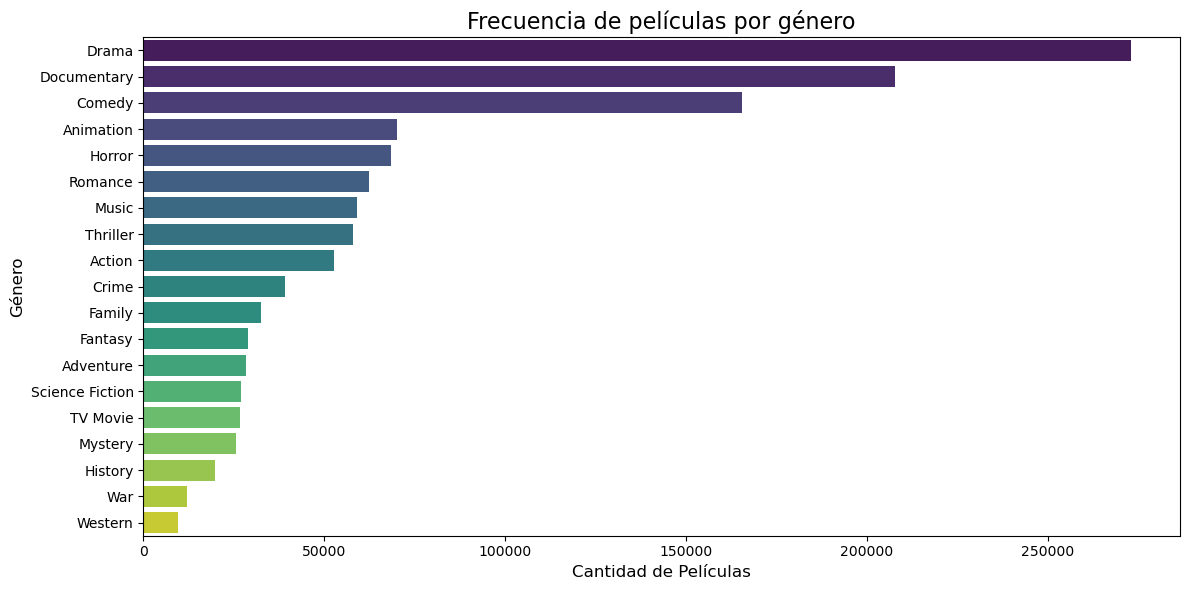

In [17]:

# 1. Limpiar nulos en la columna de géneros para evitar errores
df_generos = df_limpio.dropna(subset=['genres']).copy()

# 2. El dataset suele traer géneros separados por comas. 
# Convertimos el texto a una lista y usamos explode para que cada género tenga su propia fila
df_generos['genre_list'] = df_generos['genres'].astype(str).str.split(', ')
df_exploded = df_generos.explode('genre_list')

# 3. Contar los géneros y tomar los 15 principales
conteo_generos = df_exploded['genre_list'].value_counts()

# 4. Configurar y crear el gráfico con Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(
    x=conteo_generos.values, 
    y=conteo_generos.index, 
    hue=conteo_generos.index, 
    palette="viridis", 
    legend=False
)

# 5. Darle formato
plt.title('Frecuencia de películas por género', fontsize=16)
plt.xlabel('Cantidad de Películas', fontsize=12)
plt.ylabel('Género', fontsize=12)
plt.tight_layout() # Ajusta los márgenes automáticamente

plt.savefig('generos.png', dpi=300, bbox_inches='tight')
print("¡Imagen guardada como 'generos.png'!")
plt.show()

#### Primera observación y análisis de Datos

In [18]:
# Convertimos la columna original (release_date) a tipo fecha
# Y extraemos el año (.dt.year) para crear la nueva columna 'release_year'
df_limpio['release_year'] = pd.to_datetime(df_limpio['release_date'], errors='coerce').dt.year

# Comprobamos que se haya creado correctamente
print("Columnas actuales que contienen 'year':")
print([col for col in df_limpio.columns if 'year' in col])

Columnas actuales que contienen 'year':
['release_year']


/tmp/ipykernel_263917/629478207.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpio['release_year'] = pd.to_datetime(df_limpio['release_date'], errors='coerce').dt.year


In [19]:
# 1. Calcular la frecuencia y dejar que value_counts() ordene por cantidad (de mayor a menor)
top_anios = df_limpio['release_year'].value_counts().reset_index()

# 2. Renombrar las columnas
top_anios.columns = ['Año', 'Cantidad de Películas']

# 3. Limpiar nulos y formatear el año a entero
top_anios = top_anios.dropna()
top_anios['Año'] = top_anios['Año'].astype(int)

# 4. Mostrar el Top 10 de años con más películas
top_anios

,Año,Cantidad de Películas
0,2023,51847
1,2022,50161
2,2021,47984
3,2019,44902
4,2020,44291
...,...,...
181,2085,1
182,2069,1
183,2037,1
184,1874,1


In [20]:
# 1. Aplicamos el filtro usando | (OR)
# Encerramos cada condición entre paréntesis (es obligatorio en Pandas)
df_atipicos = df_limpio[(df_limpio['release_year'] < 1895) | (df_limpio['release_year'] > 2026)]

# 2. Contamos cuántos registros hay con esas fechas raras
cantidad_atipicos = len(df_atipicos)
print(f"Hay {cantidad_atipicos} películas con años fuera de rango (< 1895 o > 2026).")

# 3. Mostramos algunas de esas películas para ver qué está pasando
# Seleccionamos solo el título y el año para que sea más fácil de leer
df_atipicos[['title', 'release_year']]

Hay 927 películas con años fuera de rango (< 1895 o > 2026).


,title,release_year
12387,Roundhay Garden Scene,1888.0
16933,Traffic Crossing Leeds Bridge,1888.0
19114,Passage of Venus,1874.0
19697,Dickson Experimental Sound Film,1894.0
19801,"Monkeyshines, No. 1",1890.0
...,...,...
1322192,One Shot Left,2043.0
1322235,VERMIN,2040.0
1322296,The Farm,2029.0
1323765,Birdemic 6: Oracle Of Delphi,2029.0


In [21]:
# 1. Cantidad de películas antes de 1895
antes_1895 = len(df_limpio[df_limpio['release_year'] < 1895])
print(f"Películas antes de 1895: {antes_1895}")

# 2. Cantidad de películas después de 2026
despues_2026 = len(df_limpio[df_limpio['release_year'] > 2026])
print(f"Películas después de 2026: {despues_2026}")

Películas antes de 1895: 224
Películas después de 2026: 703


¡Imagen guardada como 'histograma_decadas.png'!


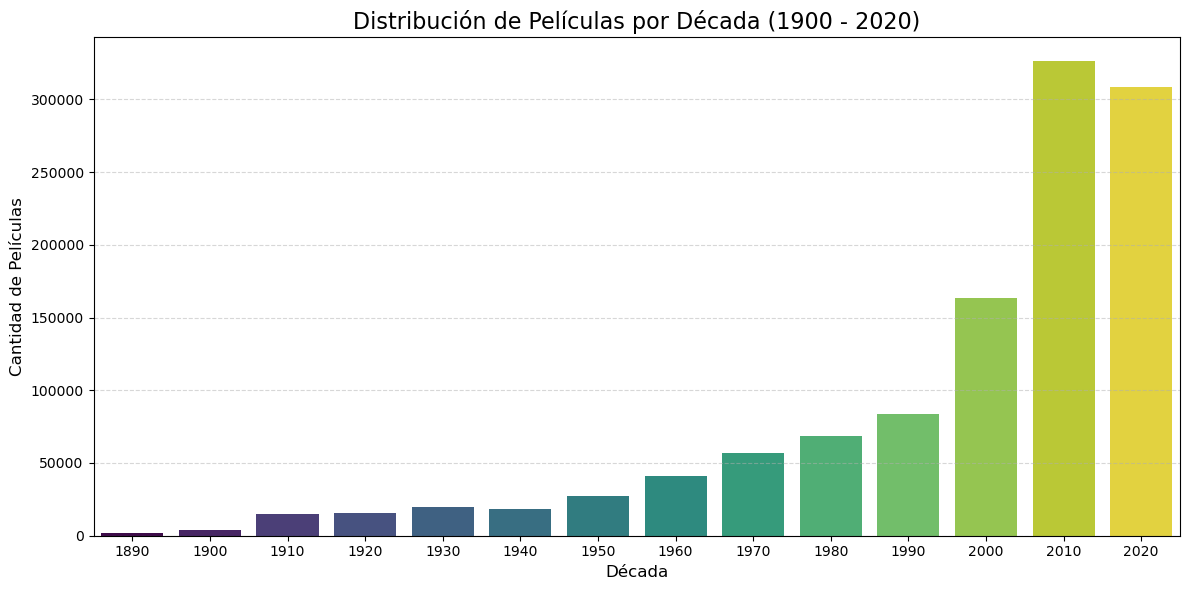

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Quitar los valores nulos en el año para que no falle el cálculo matemático
df_decadas = df_limpio.dropna(subset=['release_year']).copy()

# 2. Crear la columna 'decade' con el truco de la división entera
df_decadas['decade'] = (df_decadas['release_year'] // 10) * 10

# 3. Convertir a entero para que no se vea con decimales (ej. 1990.0)
df_decadas['decade'] = df_decadas['decade'].astype(int)

# 4. Filtrar para quedarnos con décadas reales del cine (1900 hasta la década actual)
# Esto evita décadas erróneas como "1800" o "2990" por errores del dataset
df_decadas = df_decadas[(df_decadas['decade'] >= 1890) & (df_decadas['decade'] <= 2020)]

# 5. Contar las películas por década y ordenar cronológicamente
conteo_decadas = df_decadas['decade'].value_counts().sort_index()

# 6. Configurar el gráfico
plt.figure(figsize=(12, 6))

# Usamos barplot porque para intervalos categóricos como las décadas queda mucho más prolijo
sns.barplot(
    x=conteo_decadas.index, 
    y=conteo_decadas.values, 
    palette='viridis',
    legend=False,
    hue=conteo_decadas.index # Hue asignado para que la paleta se aplique correctamente en versiones nuevas de Seaborn
)

# 7. Formato y etiquetas
plt.title('Distribución de Películas por Década (1900 - 2020)', fontsize=16)
plt.xlabel('Década', fontsize=12)
plt.ylabel('Cantidad de Películas', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig('histograma_decadas.png', dpi=300, bbox_inches='tight')
print("¡Imagen guardada como 'histograma_decadas.png'!")

# Mostrar el gráfico en el notebook
plt.show()

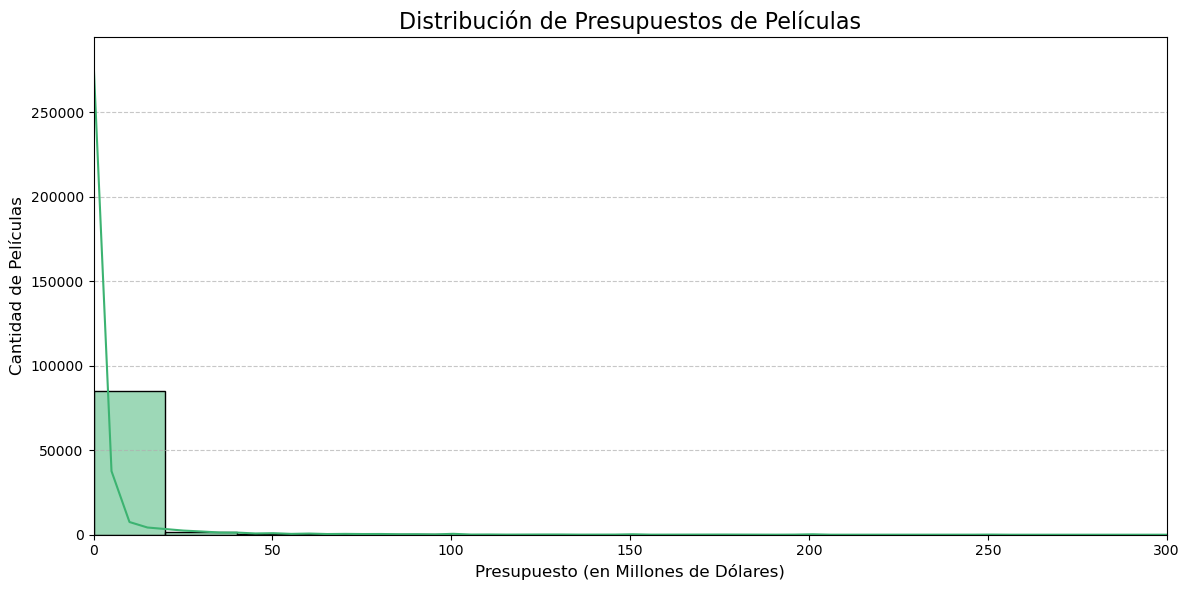

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Quedarnos solo con las películas que reportaron su presupuesto (> 0)
df_presupuestos = df_limpio[df_limpio['budget'] > 0].copy()

# 2. Dividir el presupuesto por 1 millón para facilitar la lectura del gráfico
df_presupuestos['budget_millions'] = df_presupuestos['budget'] / 1_000_000

# 3. Configurar el tamaño del lienzo
plt.figure(figsize=(12, 6))

# 4. Crear el histograma con Seaborn
# El parámetro 'bins' es el que define la cantidad de rangos/intervalos.
# Puedes probar cambiarlo a 20 o 100 para ver cómo se agrupan los datos.
sns.histplot(
    data=df_presupuestos, 
    x='budget_millions', 
    bins=50, 
    color='mediumseagreen', 
    kde=True # Agrega una curva de tendencia suave sobre las barras
)

# 5. Formato y etiquetas
plt.title('Distribución de Presupuestos de Películas', fontsize=16)
plt.xlabel('Presupuesto (en Millones de Dólares)', fontsize=12)
plt.ylabel('Cantidad de Películas', fontsize=12)

# 6. Acortar el eje X (Opcional)
# Hay algunas películas que costaron 400M+ que estiran mucho el gráfico hacia la derecha.
# Limitamos el eje X a 300 millones para ver mejor dónde se concentra la mayoría.
plt.xlim(0, 300) 

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Graficando boxplot para 89,141 películas con presupuesto válido...


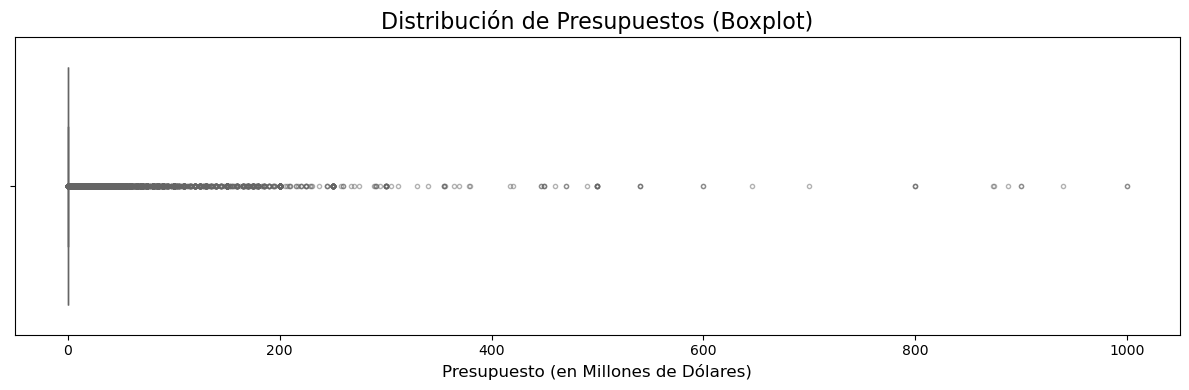

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Supongamos que df_limpio ya existe y está cargado en memoria...

# 1. Preparación de Datos y Filtro (Verificación Crucial)
# Muchas de las 1M de películas no tienen presupuesto reportado (es 0).
# Es vital chequear que nos queden datos numéricos válidos.
df_presupuestos = df_limpio[df_limpio['budget'] > 0].copy()
df_presupuestos['budget_millions'] = df_presupuestos['budget'] / 1_000_000

# VERIFICACIÓN CLAVE: Si está vacío, avisar y no graficar.
if len(df_presupuestos) == 0:
    print("¡Error! Tu dataset filtrado está vacío.")
    print("No hay películas con presupuesto mayor a 0 para graficar un Boxplot.")
    print("Revisa la carga inicial de tus datos.")
else:
    print(f"Graficando boxplot para {len(df_presupuestos):,} películas con presupuesto válido...")

    # 2. Configurar lienzo
    plt.figure(figsize=(12, 4))

    # 3. Crear Boxplot (Si hay datos)
    sns.boxplot(
        x=df_presupuestos['budget_millions'],
        color='coral',
        flierprops={'marker': '.', 'color': 'gray', 'alpha': 0.5} # Estilo de los puntos atípicos
    )

    # 4. Formato y etiquetas
    plt.title('Distribución de Presupuestos (Boxplot)', fontsize=16)
    plt.xlabel('Presupuesto (en Millones de Dólares)', fontsize=12)
    plt.tight_layout()

    # --- CÓDIGO PARA GUARDAR LA IMAGEN (OPCIONAL) ---
    # Si quieres guardar la imagen, quita el '#' de la línea de abajo.
    # ¡Debe ir ANTES de plt.show()!
    plt.savefig('boxplot_presupuesto.png', dpi=300, bbox_inches='tight')

    # 5. MOSTRAR (SIEMPRE AL FINAL DEL TODO DE LA CELDA EN JUPYTER)
    # plt.show() garantiza que el gráfico se imprima en el output del notebook.
    plt.show()

----------------------

### Elección del problema

Debatimos cual sería el mejor problema a resolver y **nos interesa poder predecir el revenue**, que es la ganancia que tendrían las peliculas. Dado que buscamos predecir un número flotante, se trata de un **problema de regresión** donde nuestra variable Target (u objetivo) va a ser Revenue. 

Entonces, vamos a separar el dataframe en X e y siendo y sólo la columna revenue y X el resto de los features (excepto id e imdb_id que no aportarían información par el problema elegido).



| Variable | Tipo | Descripción |
|----------|------|-------------|
| `id` | int | Identificador único de la película en TMDB. |
| `title` | str | Título de la película (generalmente en inglés o localizado). |
| `vote_average` | float | Promedio de puntuación de los usuarios (0–10). |
| `vote_count` | int | Cantidad de votos recibidos. |
| `status` | str | Estado de la película (Released, Post Production, etc.). |
| `release_date` | date | Fecha de estreno. |
| `revenue` | int | Recaudación total en dólares (USD). Muchos ceros = dato no informado. |
| `runtime` | float | Duración en minutos. |
| `adult` | bool | Indica si el contenido es para adultos. |
| `backdrop_path` | str | Ruta relativa al backdrop (imagen de fondo) en TMDB. |
| `budget` | int | Presupuesto de producción en dólares (USD). Muchos ceros = no informado. |
| `homepage` | str | URL de la página oficial de la película (muy incompleta). |
| `imdb_id` | str | Identificador en IMDb (tt...). |
| `original_language` | str | Código ISO del idioma original (en, es, fr, etc.). |
| `original_title` | str | Título original (puede diferir de `title`). |
| `overview` | str | Sinopsis / resumen de la trama. |
| `popularity` | float | Score de popularidad calculado por TMDB (métrica interna, no es rating). |
| `poster_path` | str | Ruta relativa al póster en TMDB. |
| `tagline` | str | Frase promocional / eslogan de la película. |
| `genres` | str | Géneros separados por coma o lista (ej. Action, Adventure, Science Fiction). |
| `production_companies` | str | Compañías productoras (texto o lista). |
| `production_countries` | str | Países de producción. |
| `spoken_languages` | str | Idiomas hablados en la película. |

**Notas:**
- `revenue` y `budget` = 0 suele significar “no informado”, no que la película no haya costado/recaudado nada.

In [25]:
# Seleccionamos algunos features para el ejemplo
features = ['title', 'vote_average', 'vote_count', 'status', 'release_year',
       'runtime', 'adult', 'backdrop_path', 'budget', 'homepage',
       'original_language', 'original_title', 'overview',
       'popularity', 'poster_path', 'tagline', 'genres',
       'production_companies', 'production_countries', 'spoken_languages',
       'keywords']
target   = 'revenue'

df = df_limpio[features + [target]]  #.dropna()

X = df[features]
y = df[target]

### Split del Dataset

#### No uso de Stratify

Procedemos entonces a la división del dataset en entrenamiento y testeo. Decidimos no usar stratify dado que este parámetro sirve para la distribución de las clases en problemas de clasificación, y este, como hemos dicho antes, se trata de una regresión.

#### Dimensiones de nuestro split

En nuestro análisis previo, obtuvimos que dataset cuenta con 1.514.263 registros.  Es una cantidad considerable para el algoritmo que vamos a entrenar. Entendemos que una división del 70% para entrenamiento (> 1.000.000 de registros) serían más que suficientes para el entrenamiento pudiendo hacer una buena validación de los resultados en un 30% de la muestra.

Sin embargo, como queremos hacer un algoritmo que prediga el revenue de una película ya lanzada, que consideramos que algo de revenue genero, vamos a terminar haciendo 80-20 pq al filtrar por revenue > 0 los datos quedan muy pequeños. Por lo tanto, como contamos con menos registros, quizás consideramos otros tipo de splits como 80-20, 90-10 para poder tener alguna cantidad significativa de datos de entrenamiento.

Usaremos la opción shuffle, que mezcla de manera aleatoria los registros para romper cualquier secuencialidad y brindar de aleatoridad dado que no son series temporales. 


In [26]:
# Outlier < 10

filtro_positivos = y < 0
y_menor_0 = y[filtro_positivos]
X_menor_0 = X[filtro_positivos]

print("Menores revenue 0:", y_menor_0)

filtro_positivos = y > 0
y_mayor_0 = y[filtro_positivos]
y_mayor_0 = X[filtro_positivos]

print("Mayores revenue 0:", y_mayor_0.shape)

filtro_positivos = y == 0
y_igual_0 = y[filtro_positivos]
X_igual_0 = X[filtro_positivos]

print("Igual revenue 0:", y_igual_0.shape)



Menores revenue 0: 187349   -12.0
Name: revenue, dtype: float64
Mayores revenue 0: (25587, 21)
Igual revenue 0: (1487295,)


In [27]:
# Antes del split vamos a quedarnos con los registros que tengan revenue > 0 asumiendo que 
# siempre recaudan algo las películas
# Vamos a sacar los 0 de revenue que no nos aportan informacion y van a dar error el log

filtro_positivos = y > 0
y = y[filtro_positivos]
X = X[filtro_positivos]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20, 
    random_state=42, 
    shuffle = True, 
    stratify = None 
)

print("Verificamos el split 80-20")
print(f"Dataset completo : {len(X)} filas")
print(f"X_train            : {X_train.shape[0]} filas, {X_train.shape[1]} columnas  ({X_train.shape[0]/len(X):.0%})")
print(f"y_train            : {(pd.DataFrame(y_train).shape[0])} filas, {pd.DataFrame(y_train).shape[1]} columna  ({pd.DataFrame(y_train).shape[0]/len(y):.0%})")

print(f"X_test             : {X_test.shape[0]} filas, {X_test.shape[1]} columnas   ({X_test.shape[0]/len(X):.0%})")
print(f"y_test             : {pd.DataFrame(y_test).shape[0]} filas, {pd.DataFrame(y_test).shape[1]} columna   ({pd.DataFrame(y_test).shape[0]/len(y):.0%})")

Verificamos el split 80-20
Dataset completo : 25587 filas
X_train            : 20469 filas, 21 columnas  (80%)
y_train            : 20469 filas, 1 columna  (80%)
X_test             : 5118 filas, 21 columnas   (20%)
y_test             : 5118 filas, 1 columna   (20%)


### Tratamiento de Nulos

En esta sección vamos a realizar el tratamiento de nulos. Primero vamos a observar la cantidad de nulos que tiene cada feature y decidir si vamos a hacer imputación o dropear el dato.

Listemos primero los nulos y luego pensemos si son MCAR, MAR, Estructural, o MNAR en base a la información que tengamos.

In [28]:

# 1. Calcular la cantidad absoluta de nulos por columna
nulos_absolutos = df_limpio.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
nulos_porcentaje = (nulos_absolutos / len(df_limpio)) * 100

# 3. Unir ambos cálculos en un nuevo DataFrame para visualizarlo bien en Jupyter
resumen_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos_absolutos,
    'Porcentaje (%)': nulos_porcentaje
})

# 4. Filtrar SOLO las columnas que tienen nulos y ordenarlas de mayor a menor
resumen_nulos = resumen_nulos[resumen_nulos['Cantidad de Nulos'] > 0].sort_values(by='Cantidad de Nulos', ascending=False)

# 5. Mostrar la tabla redondeando el porcentaje a 2 decimales
resumen_nulos.round(2)# 1. Calcular la cantidad absoluta de nulos por columna
nulos_absolutos = df_limpio.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
nulos_porcentaje = (nulos_absolutos / len(df_limpio)) * 100

# 3. Unir ambos cálculos en un nuevo DataFrame para visualizarlo bien en Jupyter
resumen_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos_absolutos,
    'Porcentaje (%)': nulos_porcentaje
})

# 4. Filtrar SOLO las columnas que tienen nulos y ordenarlas de mayor a menor
resumen_nulos = resumen_nulos[resumen_nulos['Cantidad de Nulos'] > 0].sort_values(by='Cantidad de Nulos', ascending=False)

# 5. Mostrar la tabla redondeando el porcentaje a 2 decimales
resumen_nulos.round(2)

,Cantidad de Nulos,Porcentaje (%)
homepage,1358321,89.78
tagline,1301176,86.01
keywords,1146953,75.81
backdrop_path,1145313,75.70
production_companies,879959,58.16
imdb_id,823355,54.42
production_countries,750389,49.60
spoken_languages,720538,47.63
genres,681079,45.02
poster_path,554596,36.66


Análisis de Nulos

* Si tenemos más del 70% podemos eliminar la columna completa. Ese es el caso de

|Feature | % nulos|
|--------|-------|
|homepage | 89.78 |
|tagline	| 86.01 |
|keywords | 75.81 |
|backdrop_path | 75.70 |

Si bien la regla general es cuando son tantos, descartarlos hay algo interesante en keywords que usando técnicas actuales de LLMs podríamos hacer o probar algun tipo de imputación en base otros datos como la descripción de la película. Mencionamos esto pero para el trabajo vamos a atarnos a la regla de dropear ls columnas con más del 70% de nulos.

* Title y original title son sólo 20 registros

Analisis para ver que los mismos registros que le faltan el titulo y titulo original. Entendemos que el titulo es una información fundamental y que no hay imputación posible asi que vamos a eliminar las filas. Al ser solo 20 filas y tener un dataset tan grande no van a reducir el tamaño de nuestros datos de manera significativa que afectara el entrenamiento del modelo.

In [29]:
nulos_title_y_original_title = df_limpio[['title','original_title']].isnull()
(nulos_title_y_original_title['title'] & nulos_title_y_original_title['original_title']).sum()  

20

* imdb_id tiene 54.42% de nulos que es un número considerable. Dado que se trata del ID del IMDB no aporta información relevante para calcular el revenue. Decidimos eliminar la columna

* Entre el 10% y 30% tenemos release_date (23.92%) y overview (23.32%) . A continuación analizamos para entender si el varlo es MAR, MNAR, MCAR o Estructural para poder pensar alguna imputación.

In [30]:
nulos_release_date = df_limpio[df_limpio['release_date'].isnull()]
nulos_release_date

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords,release_year
15506,733668,Return,6.171,129.0,Released,NaT,0.0,18.0,False,NaN,...,Eyüp decides to cross mount Ararat looking for...,3.563,NaN,NaN,NaN,NaN,NaN,"Armenian, Kurdish",NaN,NaN
15929,1091834,Return,6.980,124.0,Released,NaT,0.0,92.0,False,NaN,...,RETURN tells the story of a retired Green Bere...,4.444,NaN,A retired Green Beret returns to Vietnam with ...,NaN,NaN,NaN,NaN,NaN,NaN
30015,614840,Box,5.000,44.0,Released,NaT,5.0,90.0,False,NaN,...,"A group of friends try to defeat an evil king,...",1.553,NaN,Box Rocks!,NaN,NaN,NaN,NaN,NaN,NaN
33703,823711,kino-react,6.200,37.0,Released,NaT,0.0,0.0,False,NaN,...,test api requests for kinosakartvelo movie web...,1.307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33747,1043332,I am,9.338,37.0,Released,NaT,49110.0,88.0,False,NaN,...,A young man who writes avant-garde plays in th...,3.968,/oQI0E0C8ERiKyUxrIXKLkKm2PXX.jpg,NaN,NaN,NaN,NaN,Russian,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514200,919729,Les femmes aux filets,0.000,0.0,Released,NaT,0.0,0.0,False,NaN,...,NaN,0.600,NaN,NaN,Documentary,NaN,NaN,NaN,NaN,NaN
1514205,919722,Our Pet,0.000,0.0,Released,NaT,0.0,0.0,False,NaN,...,Baby Peggy short – AKA Too Many Lovers,0.600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1514211,919671,Doggie Bag,0.000,0.0,Released,NaT,0.0,47.0,True,NaN,...,It all starts when Kyle takes a walk in the pa...,0.600,NaN,An animal lover unleashes her passion. She lov...,NaN,NaN,NaN,NaN,NaN,NaN
1514236,919686,Enemies Within the Church,0.000,0.0,Released,NaT,0.0,132.0,False,/ccbKZAuqzYtSFelYEJdyfhb2Wpz.jpg,...,"""Enemies Within: The Church"" shows evidence fo...",0.600,/gOsEViaqrQ8Z26otURdCQ8umgCh.jpg,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
nulos_overview = df_limpio[df_limpio['overview'].isnull()]
nulos_overview

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords,release_year
7640,42436,Natale in crociera,4.935,387.0,Released,2007-12-14,0.0,103.0,False,/iweTLbiGNv42fNcgQTmg19n0s0T.jpg,...,NaN,5.520,/n83LsfQCPReYembtNtuGwqUkUOS.jpg,NaN,Comedy,Filmauro,Italy,Italian,"cruise ship, cinepanettone",2007.0
10101,919952,Il grande giorno,6.276,252.0,Released,2022-12-22,0.0,90.0,False,/nujjJgEuMUaaslCPBFC4v3eoiAi.jpg,...,NaN,4.041,/fiJ8Qn6HmR3eupzbsR7Q2rMN2UN.jpg,NaN,Comedy,"Agidi Due, Medusa Film",Italy,"French, Italian",NaN,2022.0
10932,17413,Incognito,5.507,224.0,Released,2009-04-28,0.0,94.0,False,/2Zn2IQmVW7MWO4oXJTu2oQzM2kT.jpg,...,NaN,7.916,/wzgeFbUgDFSnVG63T0FrQOdLCc1.jpg,NaN,Comedy,"Same Player, Pathé, SCOPE Pictures, Weber Inve...",France,French,NaN,2009.0
10959,154512,Lightning Strike,5.283,223.0,Released,2012-12-13,0.0,104.0,False,/ynoNkrU19q4yMcNXd2YEEGOyzcw.jpg,...,NaN,5.263,/o538evS1FqeftSKI7ixT2efkZKt.jpg,NaN,Comedy,Filmauro,Italy,Italian,"romantic comedy, cinepanettone",2012.0
11021,244514,Colpi di fortuna,4.700,221.0,Released,2013-12-21,0.0,0.0,False,/rwgxV7s75dri2MIs8s2ZedpTw0e.jpg,...,NaN,4.050,/rWumuliOwR6yAcP6ZVo0D0kjaGR.jpg,NaN,Comedy,Filmauro,Italy,Italian,"anthology, cinepanettone",2013.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514185,919614,"17ème jour de tournage du film ""Police""",0.000,0.0,Released,1984-12-05,0.0,12.0,False,NaN,...,NaN,0.600,/rOWZRLfmLVGswtkbVIaJGffOdFV.jpg,NaN,NaN,NaN,NaN,NaN,NaN,1984.0
1514194,919728,Un fallimento perfettamente riuscito,0.000,0.0,Released,2021-12-02,0.0,0.0,False,NaN,...,NaN,0.600,/6Nsy9Is8oLOHCVhr3mgR8K2vPOD.jpg,NaN,NaN,NaN,NaN,NaN,NaN,2021.0
1514200,919729,Les femmes aux filets,0.000,0.0,Released,NaT,0.0,0.0,False,NaN,...,NaN,0.600,NaN,NaN,Documentary,NaN,NaN,NaN,NaN,NaN
1514244,919675,23 Painéis para 'La Battaglia Celeste tra Mich...,0.000,0.0,Released,2021-12-24,0.0,0.0,False,NaN,...,NaN,0.600,/7Wd3gsz6ZCzVyfR57JbZ6QYB0bJ.jpg,NaN,NaN,NaN,NaN,NaN,NaN,2021.0


La conclusion que sacamos que Overview, como se trata de una variable de texto particular a cada película, no hay un patrón que se haya perdido o una relación con otra variable, vamos a tomarla como MNAR y podríamos que buscar su valor en wikipedia o con un LLM, es decir usando un modelo especial para completarla.

Dado que aun tenemos muchos datos, vamos a decidir por el momento quitar la fila de esos pocos datos sin Overview, sin embargo, recomendamos completar con wikipedia o LLM porque creemos que de que trata la película podría tener relación con su Revenue.

Con respecto a Release Date, notamos que en general las filas sin Release Date, son filas con muchos nulos. Evaluamos cuantas de ellas tienen revenue 0.




In [32]:
nulos_rd_revenue_0 = len(nulos_release_date[nulos_release_date['revenue'] == 0])

# 2. Calcular el porcentaje que representan sobre el total de filas
nulos_porcentaje = (nulos_rd_revenue_0 / len(nulos_release_date)) * 100

# 3. Unir ambos cálculos en un nuevo DataFrame para visualizarlo bien en Jupyter
print('Cantidad de Nulos de Release Date con Revenue 0', nulos_rd_revenue_0)
print('Porcentaje (%)', nulos_porcentaje)
print('Cantidad de Nulos de Release Date con Revenue distinto a 0', len(nulos_release_date) - nulos_rd_revenue_0)


Cantidad de Nulos de Release Date con Revenue 0 357343
Porcentaje (%) 98.7651011163287
Cantidad de Nulos de Release Date con Revenue distinto a 0 4468


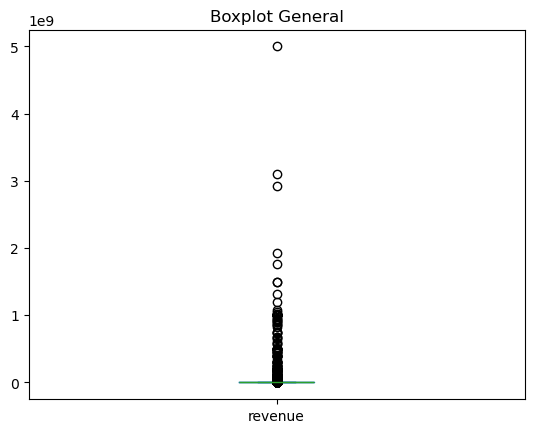

In [33]:
resto = nulos_release_date[nulos_release_date['revenue'] > 0]

# Genera un único boxplot para la columna 'valores'
resto['revenue'].plot(kind='box')

plt.title('Boxplot General')
plt.show()

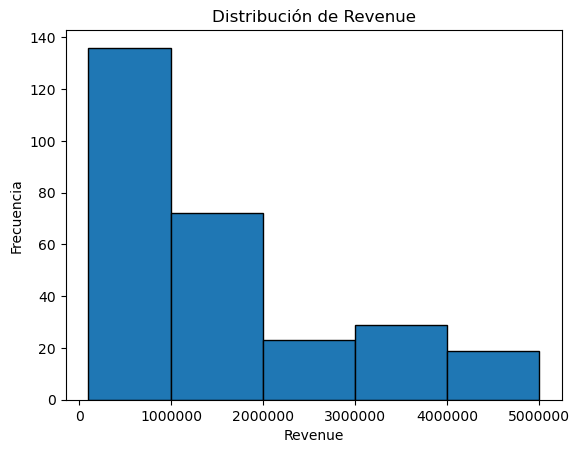

In [34]:
resto = nulos_release_date[nulos_release_date['revenue'] > 100000]

# Definir los bordes de los bins desde 100,000 hasta 5,000,000
cortes = [100000, 1000000, 2000000, 3000000, 4000000, 5000000]

# Crear el histograma
resto['revenue'].plot(kind='hist', bins=cortes, edgecolor='black')

plt.title('Distribución de Revenue')
plt.xlabel('Revenue')
plt.ylabel('Frecuencia')

# Evita que matplotlib use notación científica (ej. 1e6) en el eje X
plt.ticklabel_format(style='plain', axis='x') 

plt.show()

Con lo cual, 98.76% de los nulos de release date tiene 0 revenue con lo cual podríamos eliminarlos. Sin embargo, no vemos que hacer con los 4468 registros con revenue mayor a 0.  Podría ser interesante imputarlos de alguna forma para aprovechar esos datos quizás usando alguna otra fuente de datos que nos diga la fecha de release de la película.

Continuando con nuestro análisis de nulos, pasamos a aquellos que tienen entre 30% y 70%

| Feature | % nulos |
|--------|-------|
| production_companies | 58.16 | 
| imdb_id | 54.42 |
| production_countries | 49.60 | 
| spoken_languages | 47.63 |
| genres | 45.02 |
| poster_path | 36.66 |

Tanto como poster_path y imdb_id, consideramos que no suman el revenue dado que no aportan al criterio de los usuarios. Quizás, podríamos transformar poster_path en tiene poster o no y ver si las películas que indicaron poster tienen mayor revenue. Anotamos para transformarla.

Creemos que production_companies, production_countries, spoken_languages y genres podrían aportar y pensamos también posibles transformaciones. Hacemos un mayor análisis para entender como imputarlas.


In [35]:
production_data_nulos = df_limpio[['production_companies','production_countries']].isnull()
(production_data_nulos['production_companies'] & production_data_nulos['production_countries']).sum()  

650442

In [36]:
(production_data_nulos['production_companies'] ^ production_data_nulos['production_countries']).sum()  

329464

Concluimos que si bien hay muchos datos faltantes de compañias y sus paises, tenemos datos en los cuales tenemos el production_company y no el pais, y biseversa. Esos datos podermos pensarlos como MAR e incluso creemos que dentro de los mismos datos podemos tener los nombres de los paises o las compañias que nos ayuden a completar los faltantes.

In [37]:
production_data_values = df_limpio[['production_companies','production_countries']]
list(production_data_values.drop_duplicates().sort_values(by=['production_companies','production_countries']).values)

[array(['"A ME AND YOU MOTION PICTURE"', nan], dtype=object),
 array(['"A ME AND YOU MOTION PICTURE", Black Cat Media, Current Resident',
        'United States of America'], dtype=object),
 array(['"Creo" of M. Bystritsky', 'Russia'], dtype=object),
 array(['"En Teoría" Producciones', 'Peru'], dtype=object),
 array(['"Filma" Shareholders\' Association', 'Soviet Union'], dtype=object),
 array(['"G" P.C. S.A., José Frade, Televicine S.A. de C.V.', 'Spain'],
       dtype=object),
 array(['"GREEN" Productions', 'Canada'], dtype=object),
 array(['"Hypnosis Mic - Division Rap Battle" Rule the Stage Production Committee',
        'Japan'], dtype=object),
 array(['"I Used To Fuck People Like You In Prison" Records', 'Germany'],
       dtype=object),
 array(['"It Goes to 11" Productions', 'Philippines'], dtype=object),
 array(['"Just The Filter" Productions', nan], dtype=object),
 array(['"M" Films', nan], dtype=object),
 array(['"MIYAGINO" Film Partners', 'Japan'], dtype=object),
 array(['"N"

Notamos que los datos de los estudios y los paises son bastante dispersos y precisamos normalizarlos. También, esto nos puede ayudar a tener los valores correctos para imputar el pais de cada estudio. También, creemos que podemos relacionarlo con el lenguaje. Así queda cuando agregamos lenguaje.

In [38]:
production_data_values = df_limpio[['production_companies','production_countries','spoken_languages']]
list(production_data_values.drop_duplicates().sort_values(by=['production_companies','production_countries','spoken_languages']).values)

[array(['"A ME AND YOU MOTION PICTURE"', nan, 'English'], dtype=object),
 array(['"A ME AND YOU MOTION PICTURE"', nan, nan], dtype=object),
 array(['"A ME AND YOU MOTION PICTURE", Black Cat Media, Current Resident',
        'United States of America', 'English'], dtype=object),
 array(['"Creo" of M. Bystritsky', 'Russia', 'No Language'], dtype=object),
 array(['"En Teoría" Producciones', 'Peru', 'Spanish'], dtype=object),
 array(['"Filma" Shareholders\' Association', 'Soviet Union',
        'No Language'], dtype=object),
 array(['"G" P.C. S.A., José Frade, Televicine S.A. de C.V.', 'Spain',
        'Spanish'], dtype=object),
 array(['"GREEN" Productions', 'Canada', 'English'], dtype=object),
 array(['"Hypnosis Mic - Division Rap Battle" Rule the Stage Production Committee',
        'Japan', 'Japanese'], dtype=object),
 array(['"I Used To Fuck People Like You In Prison" Records', 'Germany',
        'German, English'], dtype=object),
 array(['"It Goes to 11" Productions', 'Philippines', 

Observamos que agregando Language vemos que también MAR, entonces podemos limpiar estas equivalencias entre production_companies, production_countries y lenguaje. Nos podría servir para Normalizar y para Imputar los N/A en las columnas Language y production_countries.

#### Tratamiento de nulos conclusiones

Visto el análisis anterior, vamos a proceder de la siguente manera:

* Elminar columnas:
    - **homepage**
    - **tagline**
    - **keywords**
    - **backdrop_path**
    - **imdb_id**
  

* Agregar una columna que diga si es Nulo (False) o no Nulo la columna **poster_path** e eliminarla.

* Imputar  **production_countries** y **spoken_languages** a partir de la normalización de los valores únicos de **production_companies**, **production_countries** y **spoken_languages**

* Considerar normalizar **production_companies** (algunos tienen lista y otro un valor, quizás dejar a 1 valor, también que los valores sean iguales)

* Considerar encodear **spoken_languages**, hoy se representan con una lista de lenguaje y normalizar los distintos lenguajes

* Eliminar las filas con 0 **revenue** y sin **realease_date**

* Usar LLMs para completar **Overview** con la informacion de wikipedia y **genres** u otros modelos

* Eliminar los registros con **titulo** en null y **original_title** en null que son 20 en total.


IMPORTANTE: Notamos al final que nos hubiera convenido hacer el análisis de nulos sobre X (que tiene filtrados los registros de revenue en 0) en lugar del dataset completo df_limpio. Esto hubiera cambiado las acciones y los porcentajes del análisis de nulos.
  


### Imputación de las variables y Cramer para correlacion.

Como observamos previamente, existe una interdependencia estructural entre **production_companies**, **production_countries** y **spoken_languages**:
Como se tratan de variables nominales queremos entender su correlación usando Cramer. 
El problema es complejo pq estas variables son listas y no estan normalizadas. Vamos a hacer una primer implementación.

In [39]:
production_data_values

,production_companies,production_countries,spoken_languages
0,"Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili"
1,"Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English
2,"DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin"
3,"Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish"
4,Marvel Studios,United States of America,"English, Hindi, Russian"
...,...,...,...
1514258,NaN,NaN,NaN
1514259,NaN,NaN,Polish
1514260,NaN,India,Hindi
1514261,Lucien TV,France,"Arabic, English, French, Hebrew"


In [40]:
# Mantiene el formato de Serie de Pandas y elimina los duplicados
production_companies = production_data_values['production_companies'].astype(str).str.lower().str.split(',').explode().str.strip().drop_duplicates()

# Para visualizarlo en la consola/Jupyter
display(production_companies) # o print(res)

0                                         legendary pictures
0                                                    syncopy
0                                      warner bros. pictures
1                                     lynda obst productions
2                                                  dc comics
                                 ...                        
1514071                                        gate 99 films
1514077    films en couleurs naturelles ets. a. systeme s...
1514141                          sri mahalakshmi productions
1514182                              tridev films associates
1514184                                      studio chełmska
Name: production_companies, Length: 196491, dtype: object

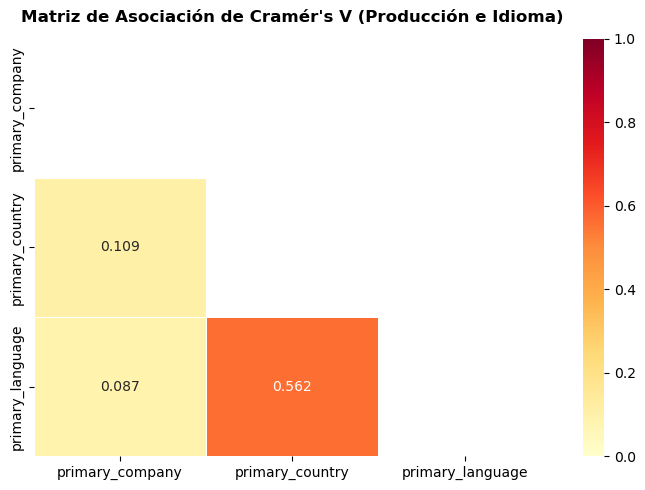

Matriz de Cramér's V calculada sobre X_train:


,primary_company,primary_country,primary_language
primary_company,1.000,0.109,0.087
primary_country,0.109,1.000,0.562
primary_language,0.087,0.562,1.000


In [41]:
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Función para calcular Cramér's V
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    if min(k - 1, r - 1) == 0 or n == 0:
        return 0.0
    return np.sqrt(chi2 / (n * min(k - 1, r - 1)))

# 2. Extraemos las entidades primarias sobre X_train ya imputado
def extraer_primario(val):
    if pd.isna(val) or str(val).lower() in ['nan', 'none', '']:
        return 'Desconocido'
    return str(val).split(',')[0].strip()

df_cramer = pd.DataFrame({
    'primary_company': X_train['production_companies'].apply(extraer_primario),
    'primary_country': X_train['production_countries'].apply(extraer_primario),
    'primary_language': X_train['spoken_languages'].apply(extraer_primario)
})

# Agrupamos las categorías principales para asegurar frecuencias esperadas válidas en Chi2
cols_prod = ['primary_company', 'primary_country', 'primary_language']
df_cramer_top = pd.DataFrame()
for c in cols_prod:
    top_cat = df_cramer[c].value_counts().head(25).index.tolist()
    if 'Desconocido' in top_cat:
        top_cat.remove('Desconocido')
    df_cramer_top[c] = df_cramer[c].apply(lambda v: v if v in top_cat else 'Otros')

v_mat = pd.DataFrame(index=cols_prod, columns=cols_prod, dtype=float)
for c1 in cols_prod:
    for c2 in cols_prod:
        if c1 == c2:
            v_mat.loc[c1, c2] = 1.0
        else:
            v_mat.loc[c1, c2] = cramers_v(df_cramer_top[c1], df_cramer_top[c2])

# 3. Graficamos la matriz con heatmap
plt.figure(figsize=(7, 5))
mask = np.triu(np.ones_like(v_mat, dtype=bool))
sns.heatmap(v_mat.astype(float), annot=True, fmt=".3f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, mask=mask)
plt.title("Matriz de Asociación de Cramér's V (Producción e Idioma)", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("cramer_v_asociacion.png", dpi=300)
plt.show()

print("Matriz de Cramér's V calculada sobre X_train:")
display(v_mat.round(3))

#### Análisis del Cramer's V

Referencia:
- 0.00 a 0.10: Asociación nula o muy débil
- 0.10 a 0.30: Asociación débil
- 0.30 a 0.50: Asociación moderada
- Mayor a 0.50: Asociación fuerte

Con lo cual lenguaje y pais tienen una asociación fuerte. Hicimos el código para imputarlso pero dado la correlación seguramente nos convenga quedarnos con uno de ellos. Vamos a elegir Lenguaje dado que Country es de la Company y quizás no tiene relación con el revenue, dado que el idioma puede indicarnos que nos dio con más paises.

In [42]:
import pandas as pd
import numpy as np

def obtener_moda(s):
    valid = s.dropna()
    valid = valid[~valid.astype(str).str.lower().isin(['nan', 'none', ''])]
    m = valid.mode()
    return m.iloc[0] if not m.empty else None
    
# 1. Función para contar elementos
def contar_elementos(valor):
    if pd.isna(valor): 
        return 0
    texto = str(valor).strip()
    if texto.lower() in ['nan', 'none', '']: 
        return 0
    return len([e for e in texto.split(',') if e.strip()])

# 2. Identificamos en X_train filas con 1 sola compañía y 1 solo país para crear un mapa preciso
cant_empresas = X_train['production_companies'].apply(contar_elementos)
cant_paises = X_train['production_countries'].apply(contar_elementos)

df_ref_empresas = X_train[(cant_empresas == 1) & (cant_paises == 1)].copy()
df_ref_empresas['production_companies'] = df_ref_empresas['production_companies'].str.strip()
df_ref_empresas['production_countries'] = df_ref_empresas['production_countries'].str.strip()

# 3. Creamos el mapa de referencia: Empresa -> País más frecuente
mapa_empresa_pais = (
    df_ref_empresas.groupby('production_companies')['production_countries']
    .agg(obtener_moda)
    .dropna()
    .to_dict()
)

# Mapa complementario: original_language -> País más frecuente
mapa_orig_pais = (
    X_train.dropna(subset=['original_language', 'production_countries'])
    .groupby('original_language')['production_countries']
    .agg(lambda s: s.apply(lambda x: str(x).split(',')[0].strip()).mode().iloc[0] if not s.empty else None)
    .dropna()
    .to_dict()
)

# 4. Función de imputación de país
def imputar_pais(fila):
    pais = str(fila['production_countries']).strip() if pd.notna(fila['production_countries']) else ''
    empresas = str(fila['production_companies']).strip() if pd.notna(fila['production_companies']) else ''
    
    # Si el país es nulo o está vacío
    if pd.isna(fila['production_countries']) or pais.lower() in ['nan', 'none', '']:
        # Prioridad 1: Por empresa productora
        if pd.notna(fila['production_companies']) and empresas.lower() not in ['nan', 'none', '']:
            primera_empresa = empresas.split(',')[0].strip()
            if primera_empresa in mapa_empresa_pais:
                return mapa_empresa_pais[primera_empresa]
        # Prioridad 2: Por idioma original
        if pd.notna(fila['original_language']) and fila['original_language'] in mapa_orig_pais:
            return mapa_orig_pais[fila['original_language']]
        return 'Desconocido'
    return fila['production_countries']

# 5. Aplicamos la imputación sobre X_train y X_test
nulos_pais_antes = X_train['production_countries'].isna().sum()
X_train['production_countries'] = X_train.apply(imputar_pais, axis=1)
X_test['production_countries'] = X_test.apply(imputar_pais, axis=1)

print(f"Imputación de Países completada:")
print(f" - Nulos antes en X_train: {nulos_pais_antes}")
print(f" - Nulos ahora en X_train: {X_train['production_countries'].isna().sum()} (Desconocidos: {(X_train['production_countries'] == 'Desconocido').sum()})")
print(f"Ejemplos del mapa Empresa -> País: {list(mapa_empresa_pais.items())[:5]}")

/tmp/ipykernel_263917/1685022301.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('original_language')['production_countries']


Imputación de Países completada:
 - Nulos antes en X_train: 5372
 - Nulos ahora en X_train: 0 (Desconocidos: 9)
Ejemplos del mapa Empresa -> País: [('(주)희원엔터테인먼트', 'South Korea'), ('1 in 10 Films', 'United States of America'), ('1-2-3 Production', 'Russia'), ('10/9 Productions', 'Russia'), ('1000 Eyes', 'United Kingdom')]


In [43]:
# 1. Creamos la tabla de referencia a partir del primer país y del idioma original
df_ref = X_train.copy()
df_ref['primer_pais'] = df_ref['production_countries'].apply(lambda x: str(x).split(',')[0].strip() if pd.notna(x) else '')
df_ref['primer_idioma'] = df_ref['spoken_languages'].apply(lambda x: str(x).split(',')[0].strip() if pd.notna(x) else '')

# Diccionario: País -> Idioma más frecuente
mapa_pais_idioma = (
    df_ref.dropna(subset=['primer_pais', 'primer_idioma'])
    .groupby('primer_pais')['primer_idioma']
    .agg(obtener_moda)
    .dropna()
    .to_dict()
)

# Diccionario: Código de Idioma Original -> Nombre de Idioma
mapa_orig_idioma = (
    df_ref.dropna(subset=['original_language', 'primer_idioma'])
    .groupby('original_language')['primer_idioma']
    .agg(obtener_moda)
    .dropna()
    .to_dict()
)

# 2. Función de imputación de idioma
def imputar_idioma(fila):
    idioma = str(fila['spoken_languages']).strip() if pd.notna(fila['spoken_languages']) else ''
    paises = str(fila['production_countries']).strip() if pd.notna(fila['production_countries']) else ''
    
    # Si el idioma es nulo o está vacío
    if pd.isna(fila['spoken_languages']) or idioma.lower() in ['nan', 'none', '']:
        # Prioridad 1: A partir del país
        if pd.notna(fila['production_countries']) and paises.lower() not in ['nan', 'none', '']:
            primer_pais = paises.split(',')[0].strip()
            if primer_pais in mapa_pais_idioma:
                return mapa_pais_idioma[primer_pais]
        # Prioridad 2: A partir del código de idioma original
        if pd.notna(fila['original_language']) and fila['original_language'] in mapa_orig_idioma:
            return mapa_orig_idioma[fila['original_language']]
        return 'Desconocido'
    return fila['spoken_languages']

# 3. Aplicamos la imputación sobre X_train y X_test
nulos_idioma_antes = X_train['spoken_languages'].isna().sum()
X_train['spoken_languages'] = X_train.apply(imputar_idioma, axis=1)
X_test['spoken_languages'] = X_test.apply(imputar_idioma, axis=1)

print(f"Imputación de Idiomas completada:")
print(f" - Nulos antes en X_train: {nulos_idioma_antes}")
print(f" - Nulos ahora en X_train: {X_train['spoken_languages'].isna().sum()} (Desconocidos: {(X_train['spoken_languages'] == 'Desconocido').sum()})")
print(f"Ejemplos del mapa País -> Idioma: {list(mapa_pais_idioma.items())[:5]}")

/tmp/ipykernel_263917/2626366618.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('original_language')['primer_idioma']


Imputación de Idiomas completada:
 - Nulos antes en X_train: 4555
 - Nulos ahora en X_train: 0 (Desconocidos: 0)
Ejemplos del mapa País -> Idioma: [('Afghanistan', 'English'), ('Albania', 'Albanian'), ('Algeria', 'Arabic'), ('Andorra', 'German'), ('Argentina', 'Spanish')]


## Desbalanceo

El desbalanceo suele ser un problema típico de una clasificación donde las métricas de accuracy suelen ser insuficientes si los datos de entrenamientos estuvieron desbalanceados.
En este trabajo, nosotros estamos trabajando con un problema de regresión donde nuestra variable objetivo es **revenue**. El desbalanceo no nos va a importar.


## Pre-procesamiento Target

Dado que revenue, es una variable expresada en millones de dólares, entendemos que para algunos algoritmos podría ser necesario escalarla. Ofrecemos adicionalmente un pre-procesamiento de la variable Target donde la transformamos en logaritmica para achicar su valor.
Medimos además el skewness.
El modelo va a tener que aplicar la inversa del logaritmo para obtener el valor real de target estimado.

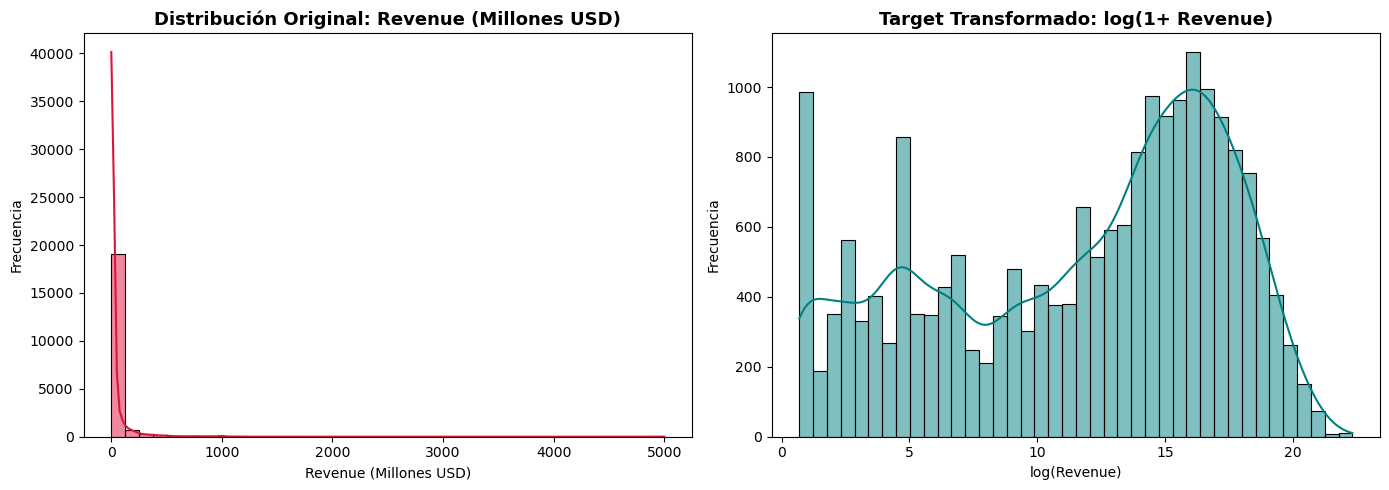

Sesgo (Skewness) original:    13.21
Sesgo (Skewness) transformado: -0.47


(20469, 21)

In [44]:

# Ahora sí puedes aplicar el logaritmo normal sin que tire error
y_train_log = np.log1p(y_train)

# Análisis visual del target: Distribución original vs Transformación logarítmica
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(y_train / 1e6, bins=40, kde=True, color='crimson')
plt.title("Distribución Original: Revenue (Millones USD)", fontsize=13, fontweight='bold')
plt.xlabel("Revenue (Millones USD)")
plt.ylabel("Frecuencia")

plt.subplot(1, 2, 2)
sns.histplot(y_train_log, bins=40, kde=True, color='teal')
plt.title("Target Transformado: log(1+ Revenue)", fontsize=13, fontweight='bold')
plt.xlabel("log(Revenue)")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.savefig("distribucion_target_revenue.png", dpi=300)
plt.show()

print(f"Sesgo (Skewness) original:    {y_train.skew():.2f}")
print(f"Sesgo (Skewness) transformado: {y_train_log.skew():.2f}")

X_train.shape

## Correlación entre variables numéricas


In [45]:
X_train.columns

Index(['title', 'vote_average', 'vote_count', 'status', 'release_year',
       'runtime', 'adult', 'backdrop_path', 'budget', 'homepage',
       'original_language', 'original_title', 'overview', 'popularity',
       'poster_path', 'tagline', 'genres', 'production_companies',
       'production_countries', 'spoken_languages', 'keywords'],
      dtype='object')

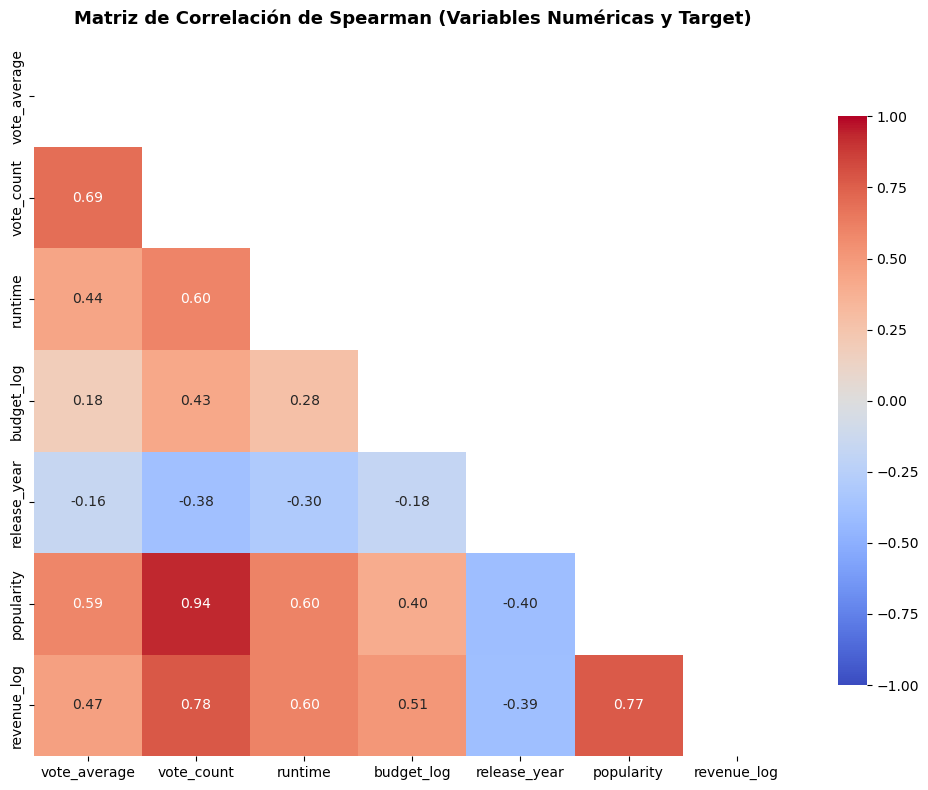

In [46]:
X_train['budget_log'] = np.log1p(X_train['budget'])
corr_vars = pd.concat([
    X_train[['vote_average','vote_count', 'runtime', 'budget_log', 'release_year', 'popularity']],
    y_train_log.rename("revenue_log")
], axis=1)

matriz_spearman = corr_vars.corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(matriz_spearman, dtype=bool))
sns.heatmap(matriz_spearman, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, mask=mask, cbar_kws={'shrink': .8})
plt.title("Matriz de Correlación de Spearman (Variables Numéricas y Target)", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("matriz_correlacion.png", dpi=300)
plt.show()

Nos preocupa la correlación alta que hay entre revenue_log con vote_count y popularity, pero en realidad nos sirve para entender 2 variables que pueden aportar mucho en la regresión. Van a estar en dataset separados X e y. Sim embargo, vote_count y popularity estan ALTAMENTE correlacionadas. Deberíamos quedarnos sólo con una, quizas la que tenga menos nulos, outliers o valores 0.

vote_average y vote_count parecen tambien estar correlacionadas. Decidimos **quedarnos con vote_count** pq puede tener relación con la cantidad de gente que vio la pelicula y **descartar vote_average y popularity**.

### Limpieza de las columnas

En este punto, ya tenemos bastante información de que columnas estan correlacionadas o tienen nulos insalvables y que no vamos a usar. Tomamos una pausa del análisis para eliminar las columnas que dijimos que no vamos a usar de X_train y X_test.

y_train e y_test ya están preprocesadas a esta altura.



In [47]:
print(X_train.columns)

Index(['title', 'vote_average', 'vote_count', 'status', 'release_year',
       'runtime', 'adult', 'backdrop_path', 'budget', 'homepage',
       'original_language', 'original_title', 'overview', 'popularity',
       'poster_path', 'tagline', 'genres', 'production_companies',
       'production_countries', 'spoken_languages', 'keywords', 'budget_log'],
      dtype='object')


In [48]:
X_train.head()

,title,vote_average,vote_count,status,release_year,runtime,adult,backdrop_path,budget,homepage,...,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords,budget_log
15600,The Legend of the Chupacabras,7.176,128.0,Released,2016.0,81.0,False,/3fEHPnm0KTyPWiZT6yEA3neLVHA.jpg,1600000.0,https://helloanima.com/la-leyenda-del-chupacab...,...,"Leo San Juan and his team of ""ghostbusters"" co...",9.924,/137StSquVSbMhLUB55kmRhMC8t8.jpg,NaN,"Animation, Action, Adventure, Fantasy, Horror,...",Ánima Estudios,Mexico,Spanish,"legend, urban legend, mexican legend, chupacabra",14.285515
94736,Keteke,6.600,7.0,Released,2017.0,78.0,False,/jw1tiH3Xr9WVfmgpqqmPWutxD2k.jpg,0.0,NaN,...,"It's the 1980s in rural Ghana, and Atswei is h...",2.235,/oO4Ln98bibsO7MKHPBMAtnOmcjH.jpg,NaN,"Comedy, Drama, Romance",OldFilm Productions,Ghana,"Akan, English",NaN,0.000000
3201,Song of the Sea,8.000,1290.0,Released,2014.0,93.0,False,/AaIRBsx4hpa2fVQzeCfFyOdzCEM.jpg,0.0,http://www.cartoonsaloon.ie/2009/06/feature-fi...,...,The story of the last Seal Child’s journey hom...,15.844,/3DBX7QOEzWPNcDhqXInk6GBEvhK.jpg,Let the song of the sea sway your heart...,"Family, Animation, Fantasy","Digital Graphics, Big Farm, Cartoon Saloon, Su...","Belgium, Denmark, France, Ireland, Luxembourg,...","English, Galician, Irish","fairy tale, lighthouse, folk music, lighthouse...",0.000000
68112,East of West,5.500,12.0,Released,1984.0,85.0,False,/oru8eUtHnqqKnFSXU6yhYGXFW3B.jpg,0.0,NaN,...,A village is under the yoke of two bands of th...,3.069,/sbWP9gbZUPcmuQWZbrUXvNmIsWP.jpg,NaN,"Comedy, Western",Ízaro Films,Spain,Spanish,"parody, cowboy",0.000000
5236,99 Francs,6.620,669.0,Released,2007.0,105.0,False,/wHwpdFBkvHRKS1zXptaskCFJ8BK.jpg,13442285.0,NaN,...,"Paris, France, 2001. Octave Parango, a young a...",10.657,/8yj6tkyp7dvdzkkIasX2SUmZd81.jpg,NaN,"Drama, Comedy","Pathé Distribution, Légende Films, ARTE France...",France,French,"drug abuse, paris, france, based on novel or b...",16.413916


In [49]:
print(X_train.columns)

Index(['title', 'vote_average', 'vote_count', 'status', 'release_year',
       'runtime', 'adult', 'backdrop_path', 'budget', 'homepage',
       'original_language', 'original_title', 'overview', 'popularity',
       'poster_path', 'tagline', 'genres', 'production_companies',
       'production_countries', 'spoken_languages', 'keywords', 'budget_log'],
      dtype='object')


In [50]:
X_train.shape


(20469, 22)

In [51]:
# Convertimos ambas a string temporalmente para comparar los valores reales
comparacion = df['title'].astype(str) == df['original_title'].astype(str)
conteo = comparacion.value_counts()
print(conteo)

True     1246481
False     266402
Name: count, dtype: int64


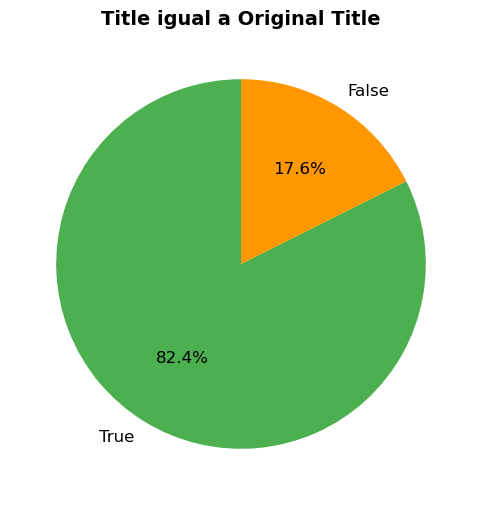

In [52]:

plt.figure(figsize=(6, 6)) # Tamaño del gráfico

conteo.plot.pie(
    autopct='%1.1f%%', 
    startangle=90, 
    colors=['#4CAF50', '#FF9800'],
    textprops={'fontsize': 12}
)

plt.title('Title igual a Original Title', fontsize=14, fontweight='bold')
plt.ylabel('') 

plt.show()

In [53]:
# Convertimos ambas a string temporalmente para comparar los valores reales
comparacion = df['status'].astype(str)
conteo = comparacion.value_counts()
print(conteo)

status
Released           1453477
In Production        27242
Post Production      17712
Planned              13136
Rumored                930
Canceled               386
Name: count, dtype: int64


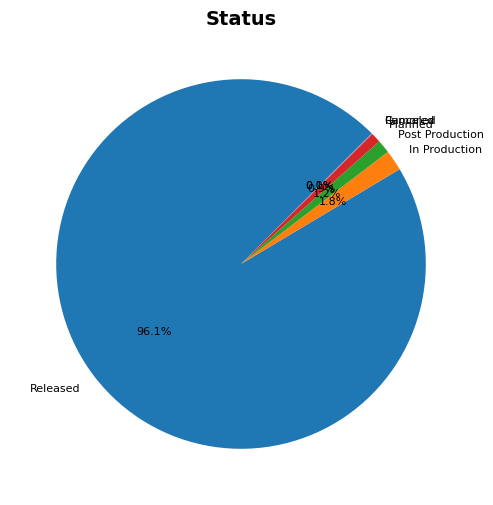

In [54]:

plt.figure(figsize=(6, 6)) # Tamaño del gráfico

conteo.plot.pie(
    autopct='%1.1f%%', 
    startangle=45, 
  
    textprops={'fontsize': 8}
)

plt.title('Status', fontsize=14, fontweight='bold')
plt.ylabel('') 

plt.show()

Concluimos que no nos interesan las filas cuyo status no sea Released dado que una vez que la película es publicada es cuando empieza a sumar Revenue

In [55]:
def drop_columns(df):
    df = df.drop('vote_average', axis=1)
    df = df.drop('budget', axis=1)
    df = df.drop('popularity', axis=1)
    df = df.drop('backdrop_path', axis=1)
    df = df.drop('homepage', axis=1)
    df = df.drop('production_countries', axis=1)
    df = df.drop('original_title', axis=1)
    df = df.drop('tagline', axis=1)
    
    return df

X_train = drop_columns(X_train)
X_test = drop_columns(X_test)


In [56]:
X_train.shape

(20469, 14)

## Tratamiento de Outliers


Para cuantificar la presencia de valores atípicos, empleamos el método clásico de **Rango Intercuartílico (IQR)** propuesto por John Tukey:
$$\text{IQR} = Q_3 - Q_1$$
Definiendo los límites de corte estadístico como:
$$\text{Límite Inferior} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Límite Superior} = Q_3 + 1.5 \times \text{IQR}$$




In [57]:
# 1. Función para diagnosticar cuantitativamente la presencia de outliers (Criterio IQR de Tukey)
def diagnostico_outliers_iqr(df_in, columnas):
    resultados = []
    for col in columnas:
        if col in df_in.columns:
            s = df_in[col].dropna()
            q1 = s.quantile(0.25)
            q3 = s.quantile(0.75)
            iqr = q3 - q1
            lim_inf = q1 - 1.5 * iqr
            lim_sup = q3 + 1.5 * iqr
            n_outliers = ((s < lim_inf) | (s > lim_sup)).sum()
            pct_outliers = (n_outliers / len(s)) * 100
            resultados.append({
                'Variable': col,
                'Q1 (25%)': round(q1, 2),
                'Mediana (50%)': round(s.median(), 2),
                'Q3 (75%)': round(q3, 2),
                'IQR': round(iqr, 2),
                'Límite Inf': round(lim_inf, 2),
                'Límite Sup': round(lim_sup, 2),
                'Cant. Outliers': n_outliers,
                '% Outliers': f"{pct_outliers:.2f}%"
            })
    return pd.DataFrame(resultados)

# Diagnóstico sobre las variables continuas presentes en X_train
vars_a_evaluar = [c for c in ['runtime', 'vote_count', 'budget_log'] if c in X_train.columns]
df_outliers_iqr = diagnostico_outliers_iqr(X_train, vars_a_evaluar)
print("=== Detección de Outliers en X_train mediante Rango Intercuartílico (IQR) ===")
display(df_outliers_iqr)

=== Detección de Outliers en X_train mediante Rango Intercuartílico (IQR) ===


,Variable,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Límite Inf,Límite Sup,Cant. Outliers,% Outliers
0,runtime,14.0,93.0,110.00,96.00,-130.00,254.00,141,0.69%
1,vote_count,0.0,15.0,315.00,315.00,-472.50,787.50,3260,15.93%
2,budget_log,0.0,6.8,15.51,15.51,-23.27,38.78,0,0.00%


In [58]:
#  Imputación de nulos y Winsorización en 'runtime'
# Imputación de runtime con la mediana de X_train (sobre valores positivos)
rt_mediana = X_train.loc[X_train['runtime'] > 0, 'runtime'].median()
X_train['runtime'] = X_train['runtime'].replace(0, np.nan).fillna(rt_mediana)
X_test['runtime'] = X_test['runtime'].replace(0, np.nan).fillna(rt_mediana)

# Aprendizaje de percentiles 1% y 99% exclusivamente sobre X_train
rt_p01 = X_train['runtime'].quantile(0.01)
rt_p99 = X_train['runtime'].quantile(0.99)
print(f"Límites de Winsorización calculados en X_train para 'runtime': P01={rt_p01:.1f} min | P99={rt_p99:.1f} min")

# Aplicación del recorte (clipping) sobre X_train y X_test
X_train['runtime_clipped'] = X_train['runtime'].clip(rt_p01, rt_p99)
X_test['runtime_clipped'] = X_test['runtime'].clip(rt_p01, rt_p99)

# Transformación Logarítmica
# Transformación log(1 + x) sobre vote_count
X_train['vote_count_log'] = np.log1p(X_train['vote_count'])
X_test['vote_count_log'] = np.log1p(X_test['vote_count'])

# Verificación de consistencia de budget_log en X_test
if 'budget_log' not in X_test.columns:
    if 'budget' in X_test.columns:
        X_test['budget_log'] = np.log1p(X_test['budget'])
    elif 'budget' in df.columns:
        X_test['budget_log'] = np.log1p(df.loc[X_test.index, 'budget'])

print(f"Sesgo (Skewness) de vote_count original:    {X_train['vote_count'].skew():.2f}")
print(f"Sesgo (Skewness) de vote_count_log:         {X_train['vote_count_log'].skew():.2f}")

Límites de Winsorización calculados en X_train para 'runtime': P01=1.0 min | P99=204.0 min
Sesgo (Skewness) de vote_count original:    6.42
Sesgo (Skewness) de vote_count_log:         0.38


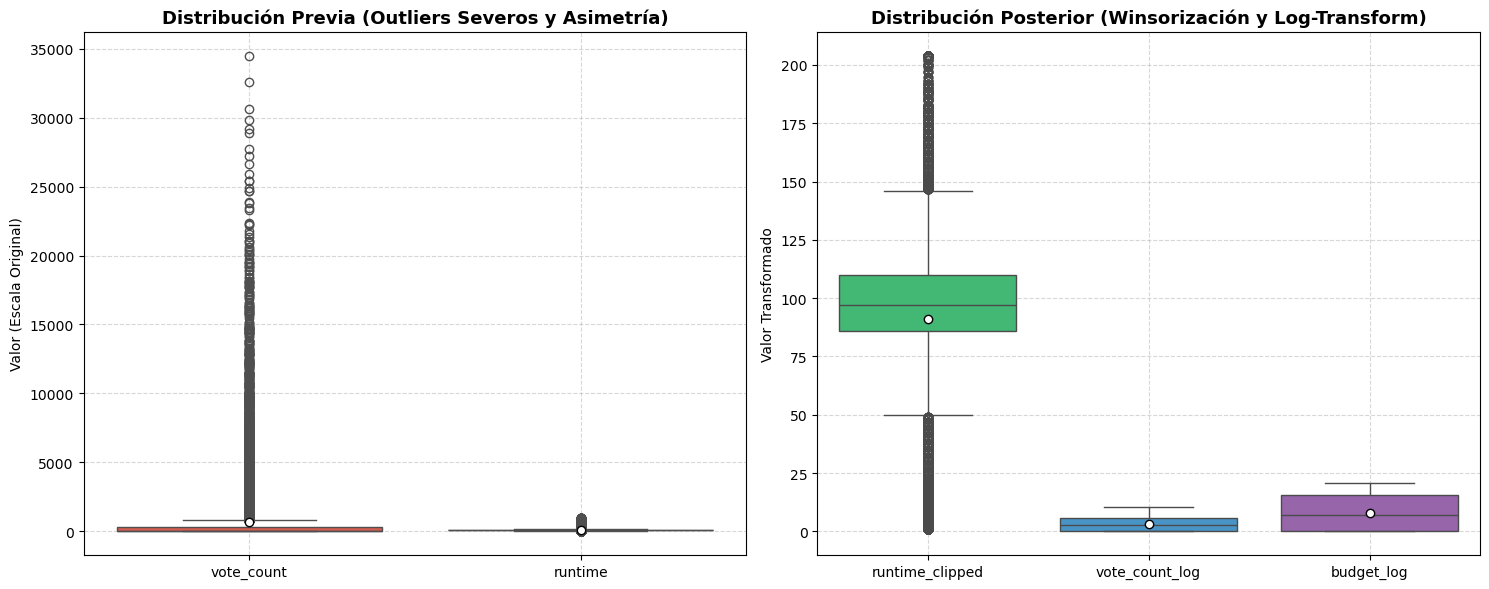

In [59]:
#  Visualización comparativa: Distribuciones Originales vs Tratadas (Boxplots)
plt.figure(figsize=(15, 6))

# Distribución previa (escala original con outliers severos)
plt.subplot(1, 2, 1)
data_previa = pd.DataFrame({
    'vote_count': X_train['vote_count'],
    'runtime': X_train['runtime']
})
sns.boxplot(data=data_previa, palette=['#E74C3C', '#E67E22'], showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
plt.title("Distribución Previa (Outliers Severos y Asimetría)", fontsize=13, fontweight='bold')
plt.ylabel("Valor (Escala Original)")
plt.grid(True, linestyle='--', alpha=0.5)

# Distribución posterior al tratamiento
plt.subplot(1, 2, 2)
cols_post = ['runtime_clipped', 'vote_count_log']
if 'budget_log' in X_train.columns:
    cols_post.append('budget_log')

sns.boxplot(data=X_train[cols_post], palette=['#2ECC71', '#3498DB', '#9B59B6'], showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"})
plt.title("Distribución Posterior (Winsorización y Log-Transform)", fontsize=13, fontweight='bold')
plt.ylabel("Valor Transformado")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("outliers_tratamiento.png", dpi=300)
plt.show()

## Feature Engineering y Codificación de Variables Categóricas


1. Descarte de **title**:
   - Es un identificador único que es distinto en cada película y parece no aportar en la generalización.

2. Productoras **is_major_studio**:
   - Como **production_companies** es una lista de diferentes estudios y creemos que hay estudios que obtienen mayor presupuesto y revenue, decidimos no descartarla. En su lugar, creamos una variable **is_major_studio** que nos sirve para concentrar la información de **production_companies** de forma simple y que refleje lo antes mencionado.
     - 1: Si la película contó con la producción de alguno de los grandes estudios de la industria (Warner Bros, Walt Disney, Universal, Paramount, Columbia, Sony, 20th Century Fox, Metro-Goldwyn-Mayer, DreamWorks, Marvel, Lucasfilm, New Line Cinema, Lionsgate).
     - 0: Producción independiente o de estudios menores.

3. One-Hot Encoding de Géneros **genres**:
   - La variable es una lista. Cada film podría tener más de un género. Por lo tanto, decidimos representarlo con 1 hot encoding, donde en la columna se indique 1 si pertenece al genero indicado.

4. One-Hot Encoding de Idioma Original **original_language**:
   También notamos que los idiomas son una lista acotada y que un mismo film, podría tener más de 1 idioma. Usamos de manera similar, 1-hot-encoding.

5. Codificación Cíclica de Mes **release_month**:
   Como vimos en clase, la variable mes se puede representar de manera cíclica usando el seno y el coseno. Creemos que el mes de release_date podría tener alguna influencia en el revenue. Por lo tanto, lo encodeamos de esa forma.
     

In [60]:
print(X_train.shape)

(20469, 16)


In [61]:
from sklearn.preprocessing import OneHotEncoder

# 1. Descarte explícito de 'title' (identificador de alta cardinalidad)
X_train = X_train.drop(columns=['title'], errors='ignore')
X_test = X_test.drop(columns=['title'], errors='ignore')

# 2. Creación de la feature binaria 'is_major_studio' a partir de production_companies
major_studios = [
    'warner', 'disney', 'universal', 'paramount', 'columbia', 
    'fox', 'sony', 'metro-goldwyn-mayer', 'mgm', 'dreamworks', 
    'marvel', 'lucasfilm', 'new line', 'lionsgate'
]
pattern_majors = '|'.join(major_studios)

X_train['is_major_studio'] = (
    X_train['production_companies'].astype(str).str.lower().str.contains(pattern_majors, regex=True).astype(int)
)
X_test['is_major_studio'] = (
    X_test['production_companies'].astype(str).str.lower().str.contains(pattern_majors, regex=True).astype(int)
)

print(f"Proporción de películas con Major Studio en Train: {X_train['is_major_studio'].mean():.2%}")
print(f"Proporción de películas con Major Studio en Test:  {X_test['is_major_studio'].mean():.2%}")

# 3. Multi-Hot Encoding de Géneros (Top 10 del cine comercial)
top_genres = ["Drama", "Comedy", "Action", "Thriller", "Adventure", 
              "Horror", "Romance", "Crime", "Science Fiction", "Family"]

genre_cols = []
train_genres_str = X_train['genres'].astype(str)
test_genres_str = X_test['genres'].astype(str)

for g in top_genres:
    col_g = f"genre_{g.lower().replace(' ', '_')}"
    genre_cols.append(col_g)
    X_train[col_g] = train_genres_str.str.contains(g, regex=False).astype(int)
    X_test[col_g] = test_genres_str.str.contains(g, regex=False).astype(int)

# 4. One-Hot Encoding de Idioma Original (Top 5 en Train, resto 'other')
top_langs = X_train['original_language'].astype(str).value_counts().head(5).index.tolist()
print(f"Top 5 idiomas aprendidos en Train: {top_langs}")

X_train['lang_grouped'] = X_train['original_language'].astype(str).apply(lambda l: l if l in top_langs else 'other')
X_test['lang_grouped'] = X_test['original_language'].astype(str).apply(lambda l: l if l in top_langs else 'other')

ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
train_lang_enc = ohe.fit_transform(X_train[['lang_grouped']])
test_lang_enc = ohe.transform(X_test[['lang_grouped']])

lang_feature_names = [f"lang_{c.replace('lang_grouped_', '')}" for c in ohe.get_feature_names_out(['lang_grouped'])]
train_lang_df = pd.DataFrame(train_lang_enc, columns=lang_feature_names, index=X_train.index)
test_lang_df = pd.DataFrame(test_lang_enc, columns=lang_feature_names, index=X_test.index)

# 5. Extracción y Codificación Cíclica de release_month (Cycle Features)
if 'release_date' in X_train.columns:
    X_train['release_month'] = pd.to_datetime(X_train['release_date'], errors='coerce').dt.month
    X_test['release_month'] = pd.to_datetime(X_test['release_date'], errors='coerce').dt.month
elif 'release_month' in X_train.columns:
    pass
elif 'release_date' in df_limpio.columns:
    X_train['release_month'] = pd.to_datetime(df_limpio.loc[X_train.index, 'release_date'], errors='coerce').dt.month
    X_test['release_month'] = pd.to_datetime(df_limpio.loc[X_test.index, 'release_date'], errors='coerce').dt.month
elif 'release_date' in df.columns:
    X_train['release_month'] = pd.to_datetime(df.loc[X_train.index, 'release_date'], errors='coerce').dt.month
    X_test['release_month'] = pd.to_datetime(df.loc[X_test.index, 'release_date'], errors='coerce').dt.month

# Imputación de nulos en mes con la moda de Train (evitando data leakage)
mes_moda = X_train['release_month'].mode().iloc[0]
X_train['release_month'] = X_train['release_month'].fillna(mes_moda)
X_test['release_month'] = X_test['release_month'].fillna(mes_moda)

# Transformación periódica cíclica a 2D (Seno y Coseno)
X_train['month_sin'] = np.sin(2 * np.pi * X_train['release_month'] / 12)
X_train['month_cos'] = np.cos(2 * np.pi * X_train['release_month'] / 12)
X_test['month_sin'] = np.sin(2 * np.pi * X_test['release_month'] / 12)
X_test['month_cos'] = np.cos(2 * np.pi * X_test['release_month'] / 12)

cycle_cols = ['month_sin', 'month_cos']

# 6. Tratamiento complementario de poster y año
if 'poster_path' in X_train.columns:
    X_train['has_poster'] = X_train['poster_path'].notnull().astype(int)
    X_test['has_poster'] = X_test['poster_path'].notnull().astype(int)
    extra_binary = ['has_poster']
else:
    extra_binary = []

if 'release_year' in X_train.columns:
    anio_mediana = X_train['release_year'].median()
    X_train['release_year'] = X_train['release_year'].fillna(anio_mediana)
    X_test['release_year'] = X_test['release_year'].fillna(anio_mediana)
    date_cols = ['release_year']
else:
    date_cols = []

print(X_train.size)
# 7. Ensamblaje final de las matrices procesadas X_train_proc y X_test_proc
num_cols_final = ['budget_log', 'vote_count_log', 'runtime_clipped'] + date_cols
engineered_cols = ['is_major_studio'] + genre_cols + cycle_cols + extra_binary

X_train_proc = pd.concat([
    X_train[num_cols_final + engineered_cols],
    train_lang_df
], axis=1)

print(X_train_proc.shape)

X_test_proc = pd.concat([
    X_test[num_cols_final + engineered_cols],
    test_lang_df
], axis=1)

print(f"\nEnsamblado final completado exitosamente con features cíclicas:")
print(f" - X_train_proc: {X_train_proc.shape[0]:,} filas x {X_train_proc.shape[1]} columnas")
print(f" - X_test_proc:  {X_test_proc.shape[0]:,} filas x {X_test_proc.shape[1]} columnas")


Proporción de películas con Major Studio en Train: 18.63%
Proporción de películas con Major Studio en Test:  18.60%
Top 5 idiomas aprendidos en Train: ['en', 'es', 'fr', 'pt', 'zh']
634539
(20469, 23)

Ensamblado final completado exitosamente con features cíclicas:
 - X_train_proc: 20,469 filas x 23 columnas
 - X_test_proc:  5,118 filas x 23 columnas


In [62]:
print(f"Dimensiones de X_train procesado: {X_train_proc.shape[0]:,} filas, {X_train_proc.shape[1]} columnas")
print(f"Dimensiones de X_test procesado:  {X_test_proc.shape[0]:,} filas, {X_test_proc.shape[1]} columnas")
print("\nFeatures finales estructuradas para el modelado:")
for i, col in enumerate(X_train_proc.columns, 1):
    print(f"{i:2d}. {col}")

Dimensiones de X_train procesado: 20,469 filas, 23 columnas
Dimensiones de X_test procesado:  5,118 filas, 23 columnas

Features finales estructuradas para el modelado:
 1. budget_log
 2. vote_count_log
 3. runtime_clipped
 4. release_year
 5. is_major_studio
 6. genre_drama
 7. genre_comedy
 8. genre_action
 9. genre_thriller
10. genre_adventure
11. genre_horror
12. genre_romance
13. genre_crime
14. genre_science_fiction
15. genre_family
16. month_sin
17. month_cos
18. has_poster
19. lang_es
20. lang_fr
21. lang_other
22. lang_pt
23. lang_zh


## Escalamiento y Normalización


In [63]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_proc), columns=X_train_proc.columns, index=X_train_proc.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_proc), columns=X_test_proc.columns, index=X_test_proc.index)

print("Verificación de escala en X_train_scaled:")
print(f"Media promedio de los features: {X_train_scaled.mean().mean():.4f} (esperado ~ 0.0)")
print(f"Desvío estándar promedio:       {X_train_scaled.std().mean():.4f} (esperado ~ 1.0)")

Verificación de escala en X_train_scaled:
Media promedio de los features: -0.0000 (esperado ~ 0.0)
Desvío estándar promedio:       1.0000 (esperado ~ 1.0)


## Reducción de Dimensionalidad


Extracción de Features: Análisis de Componentes Principales (PCA)



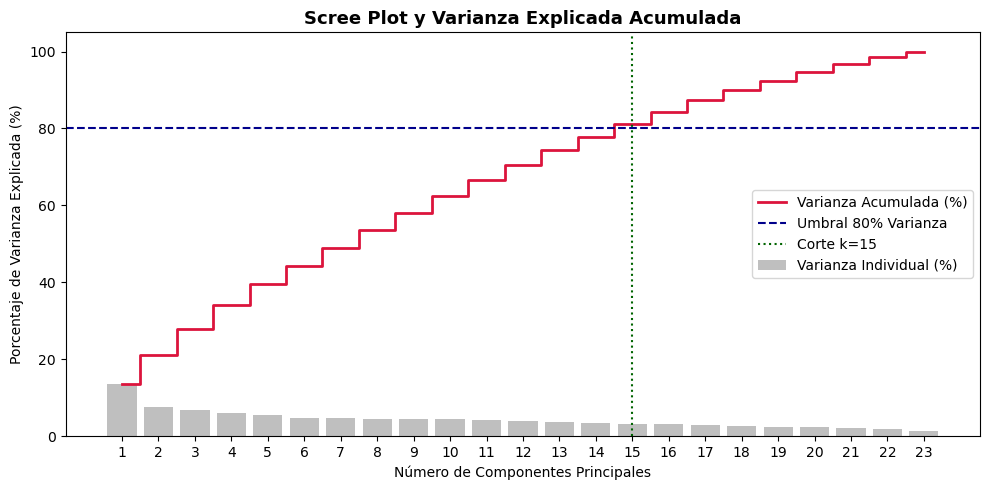

Varianza explicada por PC1: 13.63%
Varianza explicada por PC2: 7.49%
Varianza explicada acumulada con 15 componentes: 81.15%


In [64]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train_scaled)

exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)
k_80 = np.argmax(cum_var >= 0.80) + 1

plt.figure(figsize=(10, 5))
components_range = np.arange(1, len(cum_var) + 1)
plt.bar(components_range, exp_var * 100, alpha=0.5, color='gray', label='Varianza Individual (%)')
plt.step(components_range, cum_var * 100, where='mid', color='crimson', linewidth=2, label='Varianza Acumulada (%)')
plt.axhline(y=80, color='darkblue', linestyle='--', linewidth=1.5, label='Umbral 80% Varianza')
plt.axvline(x=k_80, color='darkgreen', linestyle=':', linewidth=1.5, label=f'Corte k={k_80}')

plt.title("Scree Plot y Varianza Explicada Acumulada", fontsize=13, fontweight='bold')
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Porcentaje de Varianza Explicada (%)")
plt.xticks(components_range)
plt.legend(loc='center right')
plt.tight_layout()
plt.savefig("pca_varianza_acumulada.png", dpi=300)
plt.show()

print(f"Varianza explicada por PC1: {exp_var[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {exp_var[1]*100:.2f}%")
print(f"Varianza explicada acumulada con {k_80} componentes: {cum_var[k_80-1]*100:.2f}%")

## Conclusiones

Nuestro dataset quedó de la siguiente forma:

In [65]:
print(X_train_proc.columns)

# Mostrar la cantidad de registros en los conjuntos de Train y Test
print(f"\nCantidad de registros en el conjunto de entrenamiento (Train): {X_train_proc.shape[0]}")
print(f"Cantidad de registros en el conjunto de validación/prueba (Test): {X_test_proc.shape[0]}")

X_train_proc.head()


Index(['budget_log', 'vote_count_log', 'runtime_clipped', 'release_year',
       'is_major_studio', 'genre_drama', 'genre_comedy', 'genre_action',
       'genre_thriller', 'genre_adventure', 'genre_horror', 'genre_romance',
       'genre_crime', 'genre_science_fiction', 'genre_family', 'month_sin',
       'month_cos', 'has_poster', 'lang_es', 'lang_fr', 'lang_other',
       'lang_pt', 'lang_zh'],
      dtype='object')

Cantidad de registros en el conjunto de entrenamiento (Train): 20469
Cantidad de registros en el conjunto de validación/prueba (Test): 5118


,budget_log,vote_count_log,runtime_clipped,release_year,is_major_studio,genre_drama,genre_comedy,genre_action,genre_thriller,genre_adventure,...,genre_science_fiction,genre_family,month_sin,month_cos,has_poster,lang_es,lang_fr,lang_other,lang_pt,lang_zh
15600,14.285515,4.859812,81.0,2016.0,0,0,0,1,0,1,...,0,1,-0.866025,5.000000e-01,1,1.0,0.0,0.0,0.0,0.0
94736,0.000000,2.079442,78.0,2017.0,0,1,1,0,0,0,...,0,0,1.000000,6.123234e-17,1,0.0,0.0,0.0,0.0,0.0
3201,0.000000,7.163172,93.0,2014.0,0,0,0,0,0,0,...,0,1,-1.000000,-1.836970e-16,1,0.0,0.0,0.0,0.0,0.0
68112,0.000000,2.564949,85.0,1984.0,0,0,1,0,0,0,...,0,0,0.500000,8.660254e-01,1,1.0,0.0,0.0,0.0,0.0
5236,16.413916,6.507278,105.0,2007.0,0,1,1,0,0,0,...,0,0,-1.000000,-1.836970e-16,1,0.0,1.0,0.0,0.0,0.0
